In [1]:

%matplotlib inline
%load_ext autoreload
%autoreload 2

import gc

import joblib
import pandas as pd
import torch
from imblearn.pipeline import Pipeline
from numpy import set_printoptions
from sklearn import set_config
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder

from csm500_project.constant import RAW_TRAIN_DATASET_X_PATH, RAW_TRAIN_DATASET_Y_PATH, INFERRED_TARGET_FIELD, \
    RAW_TEST_DATASET_X_PATH, RAW_TEST_DATASET_Y_PATH, BAGGING_CLASSIFIER_KNEIGHBOURS_DUMP
from csm500_project.continuous_data_analysis import CONTINUOUS_DATA_FIELDS
from csm500_project.discrete_data_analysis import DROPPED_CATEGORIES, HIGH_CARDINALITY_ENCODED_CATEGORIES, \
    LOW_CARDINALITY_ENCODED_CATEGORIES, X_ORDINAL_ENCODED_CATEGORIES
from csm500_project.ensemble_model_development import run_kneighbours_bagging_classifier_pipeline, \
    run_random_forest_pipeline, run_adaboost_decision_tree_pipeline
from csm500_project.model_development import run_model_pipeline
from csm500_project.model_pipeline import get_build_model_pipeline
from csm500_project.shap_analysis import run_shap_analysis, run_shap_inconsistency_analysis
from csm500_project.target_distribution import plot_target_distribution
from csm500_project.util import split_primary_physical_datasets

set_config(display="diagram", transform_output="pandas")
set_printoptions(precision=2, linewidth=250)

x_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_X_PATH)
y_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_Y_PATH)
x_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_X_PATH)
y_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_Y_PATH)

/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X-Train Null Values:
Organisation Entity                                   0
Description                                           0
Development Classification                            0
Entry Date Year Of Transfer                           0
Entry Date Quarter Of Transfer                        0
Decision Date Year Of Transfer                        0
Decision Date Quarter Of Transfer                     0
LSOA Code                                             0
Council Code                                          0
IMD Rank                                              0
IMD Decile                                            0
In Conservation Area                                  0
Listing Grade                                         0
Geohazards Collapsible Deposits Susceptibility        0
Geohazards Compressible Ground Susceptibility         0
Geohazards Landslides Susceptibility                  0
Geohazards Running Sand Susceptibility                0
Geohazards Shrink Swell Sus

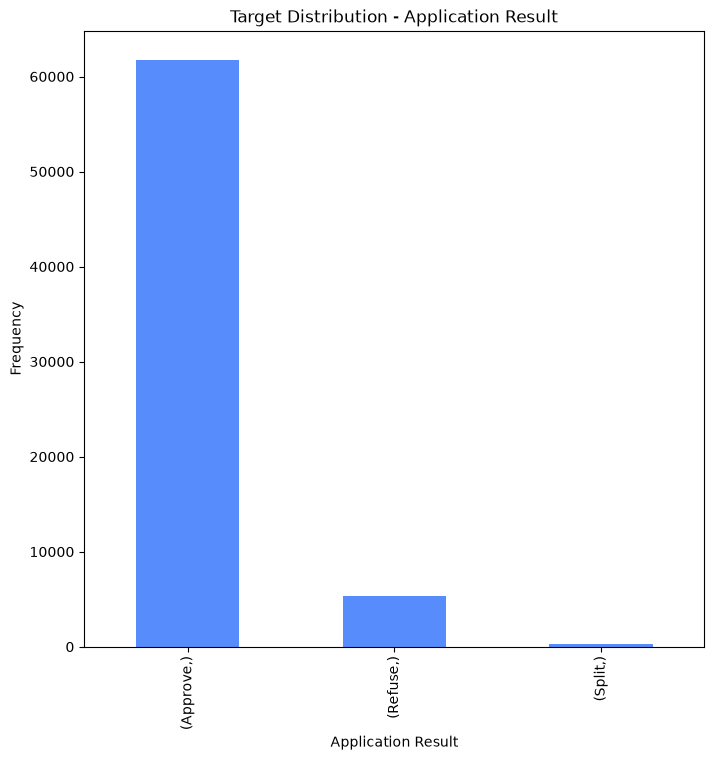

In [3]:
plot_target_distribution(x_train, y_train, "Target Distribution - Application Result")

In [2]:
target_label_encoder: LabelEncoder = LabelEncoder()


def _prepare_target(y: pd.DataFrame) -> None:
    y[INFERRED_TARGET_FIELD] = target_label_encoder.fit_transform(y[INFERRED_TARGET_FIELD])


train_datasets = split_primary_physical_datasets(x_train, y_train, False)
test_datasets = split_primary_physical_datasets(x_test, y_test, False)

primary_x_train: pd.DataFrame = train_datasets['x_primary']
physical_x_train: pd.DataFrame = train_datasets['x_physical']
primary_y_train: pd.DataFrame = train_datasets['y_primary']
physical_y_train: pd.DataFrame = train_datasets['y_physical']

_prepare_target(primary_y_train)
_prepare_target(physical_y_train)

primary_x_test: pd.DataFrame = test_datasets['x_primary']
physical_x_test: pd.DataFrame = test_datasets['x_physical']
primary_y_test: pd.DataFrame = test_datasets['y_primary']
physical_y_test: pd.DataFrame = test_datasets['y_physical']

_prepare_target(primary_y_test)
_prepare_target(physical_y_test)

print("Loaded datasets from Cache.")

Loaded datasets from Cache.


In [5]:
def _get_primary_build_model_pipeline() -> Pipeline:
    return get_build_model_pipeline([], DROPPED_CATEGORIES,
                                    X_ORDINAL_ENCODED_CATEGORIES,
                                    [c for c in HIGH_CARDINALITY_ENCODED_CATEGORIES if
                                     c != "Property Type"],
                                    LOW_CARDINALITY_ENCODED_CATEGORIES)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6044.93it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Log Regression Test Cross Val Accuracy: 0.4348 (0.0148)
Log Regression Test Cross Val Balanced Accuracy: 0.6452 (0.0157)
Log Regression Test Cross Val F1 Macro: 0.2830 (0.0083)
Log Regression Test Cross Val ROC AUC: 0.7508 (0.0135)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4972.93it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.43      0.59     30407
           1       0.16      0.65      0.25      2645
           2       0.01      0.82      0.02       116

    accuracy                           0.45     33168
   macro avg       0.37      0.63      0.29     33168
weighted avg       0.89      0.45      0.56     33168

Confusion Matrix
[[13017  9257  8133]
 [  580  1712   353]
 [   13     8    95]]


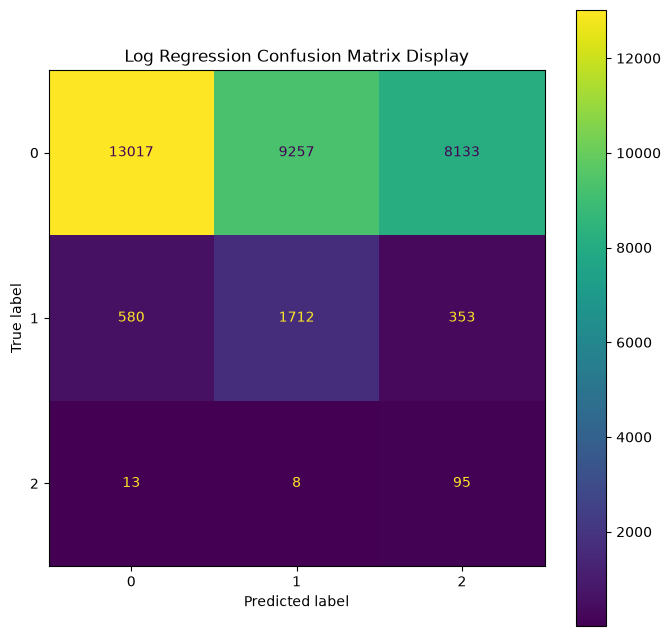

0 [0.58 0.46 0.48 ... 0.19 0.18 0.2 ]
1 [0.34 0.14 0.32 ... 0.78 0.77 0.64]
2 [0.09 0.4  0.2  ... 0.03 0.06 0.16]


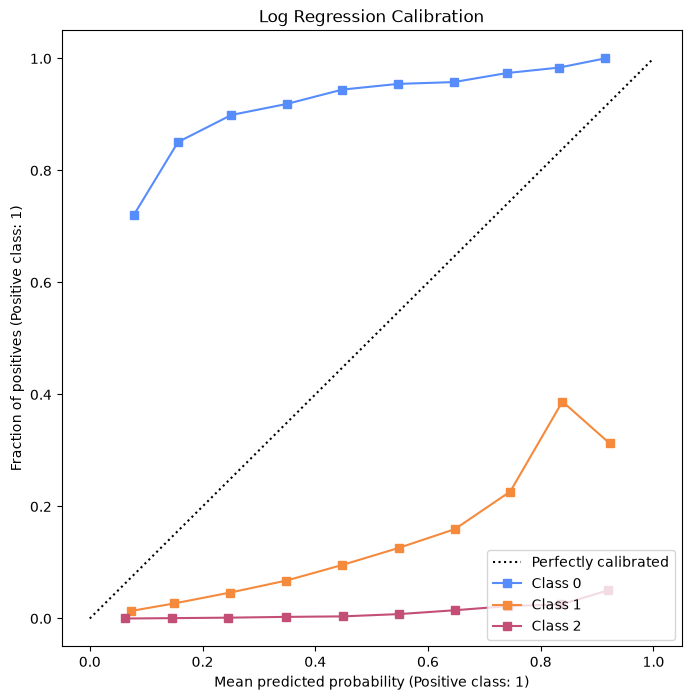

0 [0.58 0.46 0.48 ... 0.19 0.18 0.2 ]
1 [0.34 0.14 0.32 ... 0.78 0.77 0.64]
2 [0.09 0.4  0.2  ... 0.03 0.06 0.16]


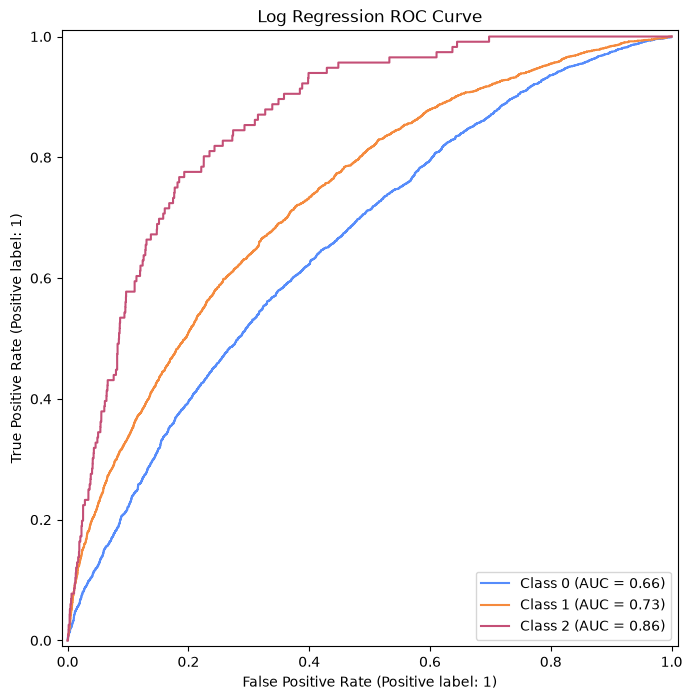

0 [0.58 0.46 0.48 ... 0.19 0.18 0.2 ]
1 [0.34 0.14 0.32 ... 0.78 0.77 0.64]
2 [0.09 0.4  0.2  ... 0.03 0.06 0.16]


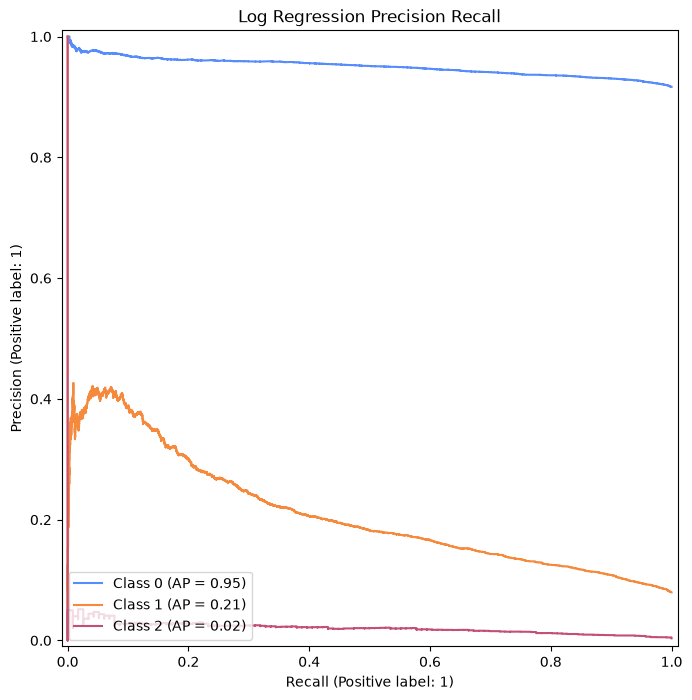

Macro Average Precision Score: 0.393


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categor

SGD Classifier Test Cross Val Accuracy: 0.5227 (0.0289)
SGD Classifier Test Cross Val Balanced Accuracy: 0.6491 (0.0199)
SGD Classifier Test Cross Val F1 Macro: 0.3156 (0.0133)
SGD Classifier Test Cross Val ROC AUC: 0.7508 (0.0135)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6870.88it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.96      0.39      0.56     30407
           1       0.15      0.69      0.24      2645
           2       0.01      0.81      0.02       116

    accuracy                           0.42     33168
   macro avg       0.37      0.63      0.27     33168
weighted avg       0.89      0.42      0.53     33168

Confusion Matrix
[[11936 10467  8004]
 [  500  1821   324]
 [   15     7    94]]


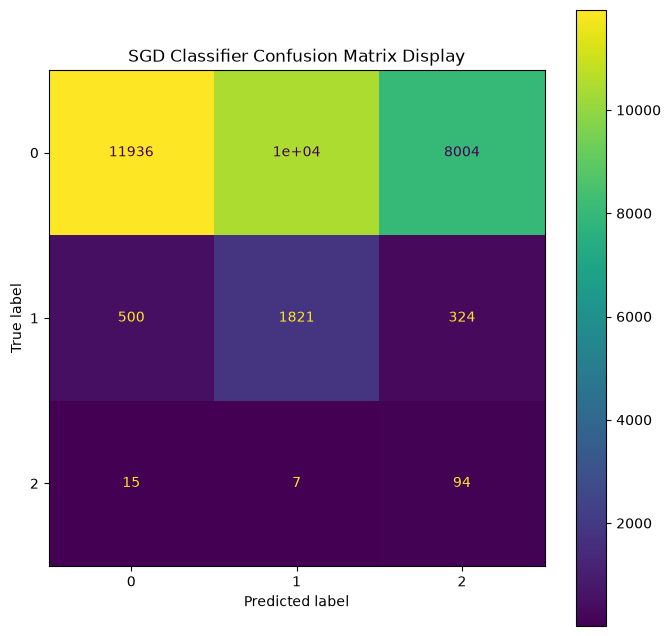

0 [0.57 0.46 0.49 ... 0.29 0.25 0.24]
1 [0.42 0.14 0.36 ... 0.71 0.75 0.71]
2 [0.01 0.41 0.15 ... 0.   0.   0.05]


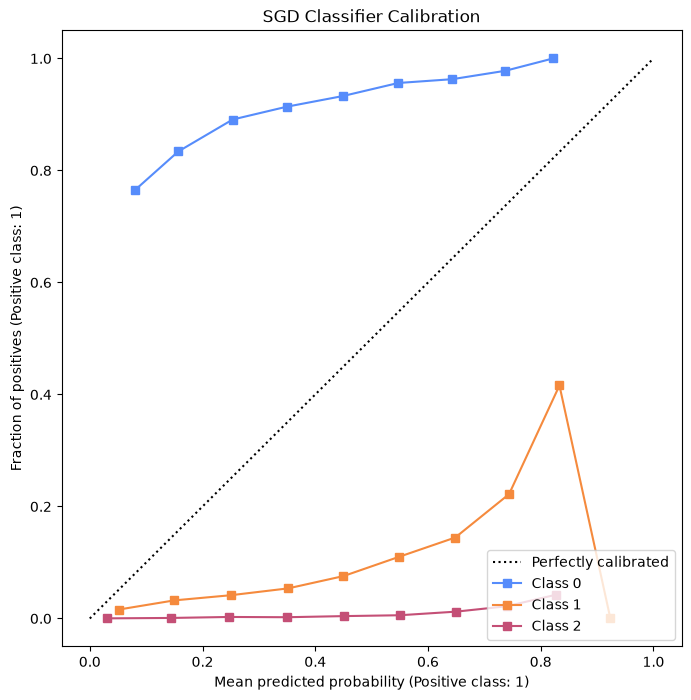

0 [0.57 0.46 0.49 ... 0.29 0.25 0.24]
1 [0.42 0.14 0.36 ... 0.71 0.75 0.71]
2 [0.01 0.41 0.15 ... 0.   0.   0.05]


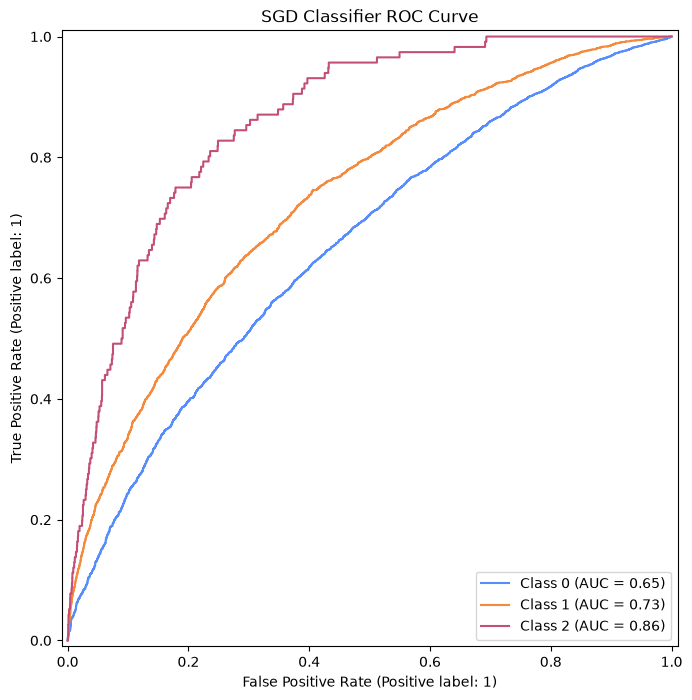

0 [0.57 0.46 0.49 ... 0.29 0.25 0.24]
1 [0.42 0.14 0.36 ... 0.71 0.75 0.71]
2 [0.01 0.41 0.15 ... 0.   0.   0.05]


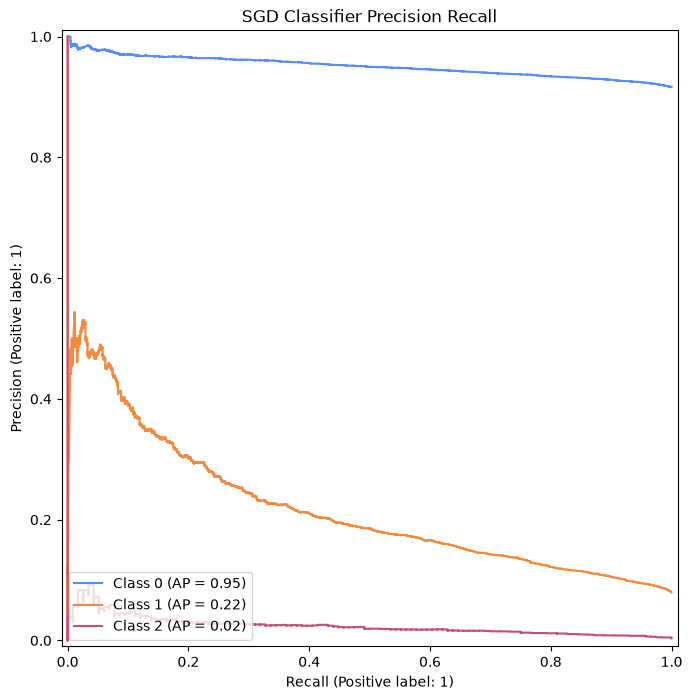

Macro Average Precision Score: 0.397


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7232.89it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

K-Neighbours Classifier Test Cross Val Accuracy: 0.7178 (0.0041)
K-Neighbours Classifier Test Cross Val Balanced Accuracy: 0.5970 (0.0083)
K-Neighbours Classifier Test Cross Val F1 Macro: 0.3993 (0.0017)
K-Neighbours Classifier Test Cross Val ROC AUC: 0.7434 (0.0106)
Classification Report
              precision    recall  f1-score   support

           0       0.96      0.74      0.84     30407
           1       0.21      0.70      0.32      2645
           2       0.05      0.41      0.09       116

    accuracy                           0.74     33168
   macro avg       0.41      0.62      0.42     33168
weighted avg       0.90      0.74      0.80     33168

Confusion Matrix
[[22576  6938   893]
 [  774  1842    29]
 [   48    20    48]]


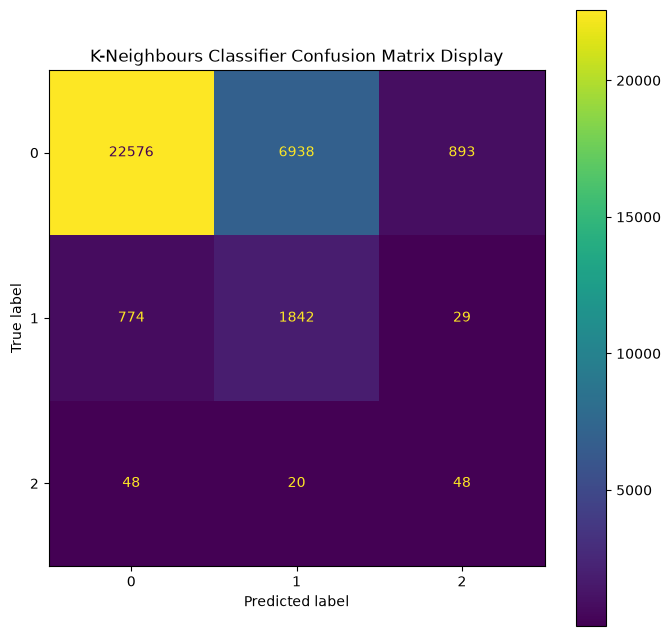

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


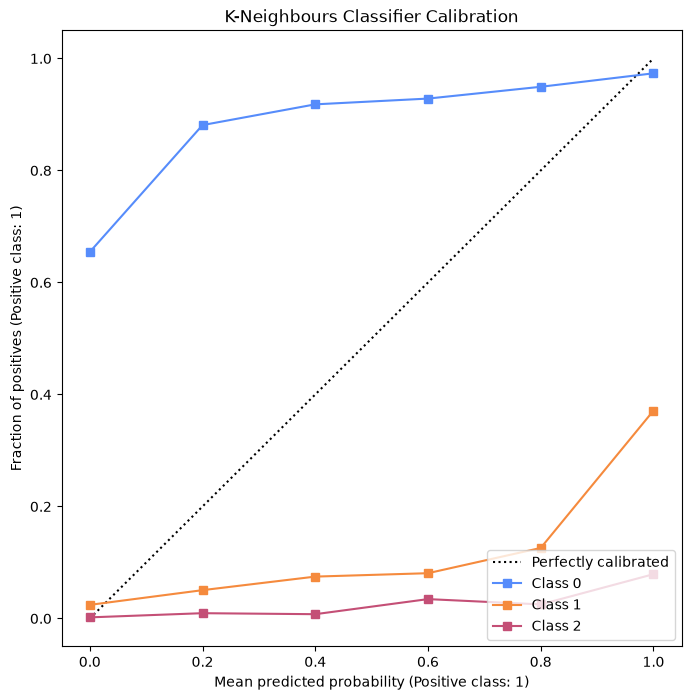

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


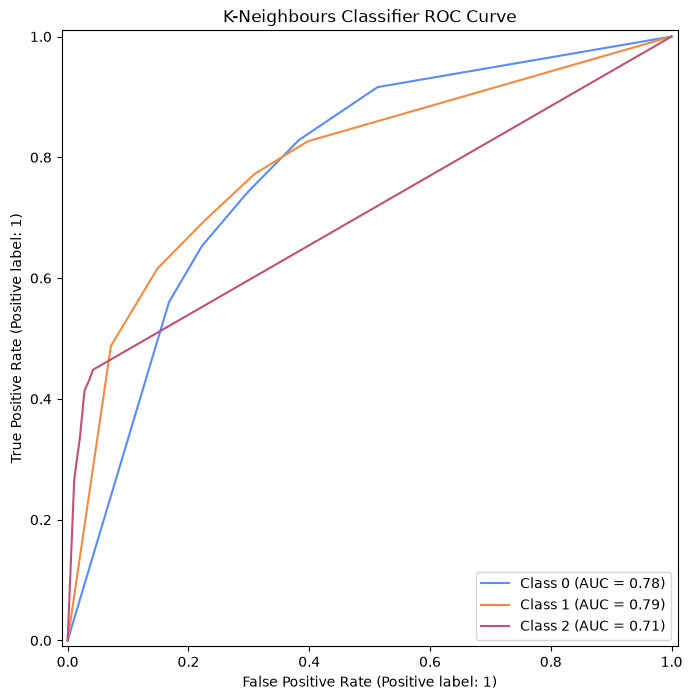

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


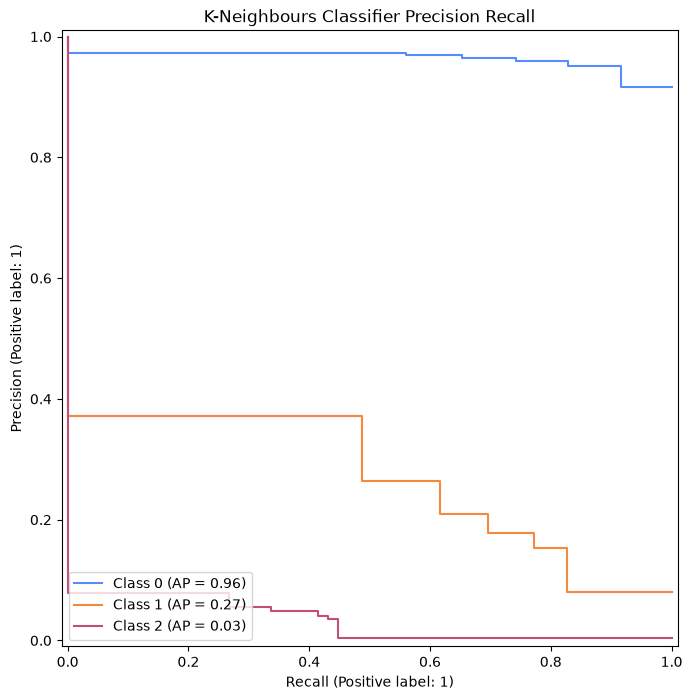

Macro Average Precision Score: 0.421


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6637.37it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Decision Tree Classifier Test Cross Val Accuracy: 0.7008 (0.0055)
Decision Tree Classifier Test Cross Val Balanced Accuracy: 0.5391 (0.0186)
Decision Tree Classifier Test Cross Val F1 Macro: 0.3729 (0.0033)
Decision Tree Classifier Test Cross Val ROC AUC: 0.7135 (0.0029)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.72      0.82     30407
           1       0.18      0.57      0.27      2645
           2       0.03      0.41      0.05       116

    accuracy                           0.70     33168
   macro avg       0.38      0.56      0.38     33168
weighted avg       0.89      0.70      0.77     33168

Confusion Matrix
[[21756  7116  1535]
 [ 1067  1516    62]
 [   54    15    47]]


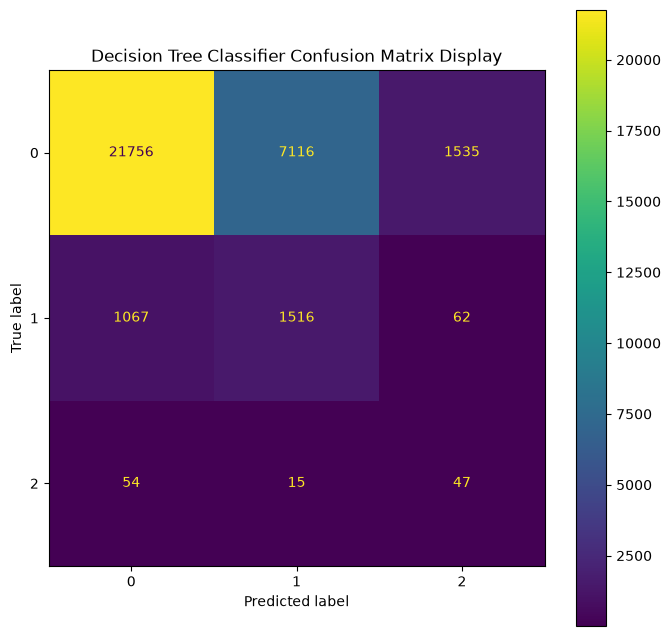

0 [1.   1.   0.88 ... 0.25 0.96 0.36]
1 [0.   0.   0.12 ... 0.75 0.04 0.64]
2 [0. 0. 0. ... 0. 0. 0.]


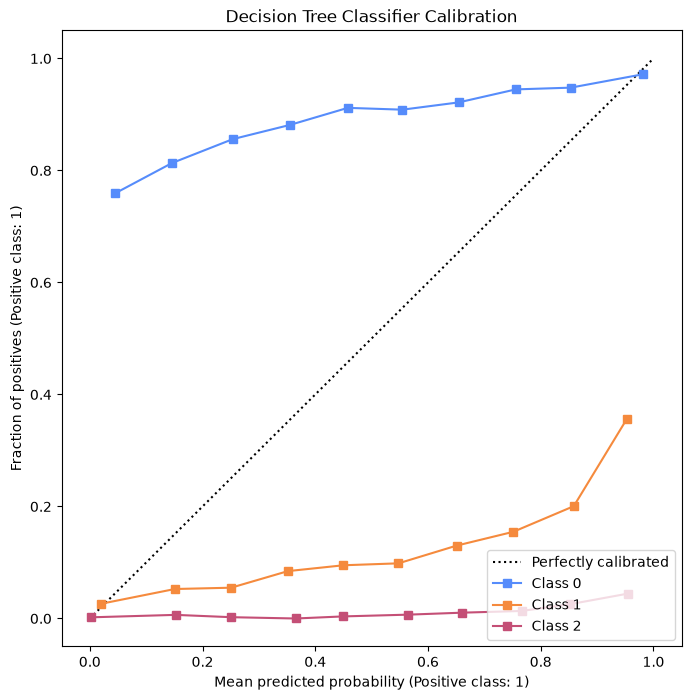

0 [1.   1.   0.88 ... 0.25 0.96 0.36]
1 [0.   0.   0.12 ... 0.75 0.04 0.64]
2 [0. 0. 0. ... 0. 0. 0.]


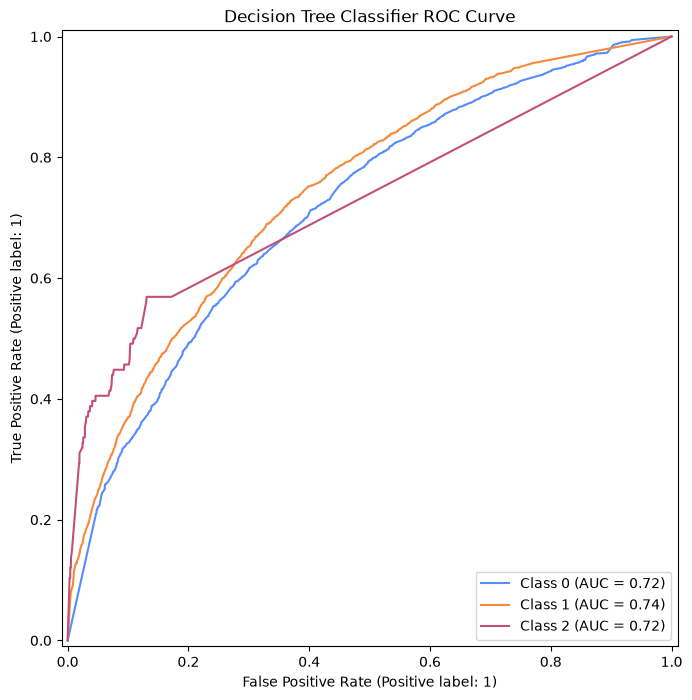

0 [1.   1.   0.88 ... 0.25 0.96 0.36]
1 [0.   0.   0.12 ... 0.75 0.04 0.64]
2 [0. 0. 0. ... 0. 0. 0.]


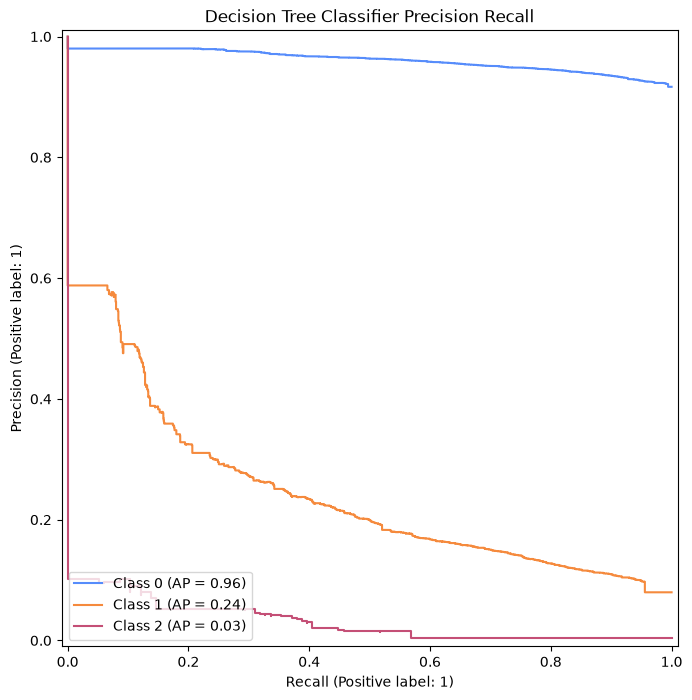

Macro Average Precision Score: 0.411


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarni

Linear SVC Test Cross Val Accuracy: 0.2468 (0.0303)
Linear SVC Test Cross Val Balanced Accuracy: 0.6096 (0.0090)
Linear SVC Test Cross Val F1 Macro: 0.1873 (0.0184)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.95      0.18      0.31     30407
           1       0.12      0.74      0.20      2645
           2       0.01      0.90      0.02       116

    accuracy                           0.23     33168
   macro avg       0.36      0.61      0.18     33168
weighted avg       0.88      0.23      0.30     33168

Confusion Matrix
[[ 5613 14509 10285]
 [  265  1959   421]
 [    4     8   104]]


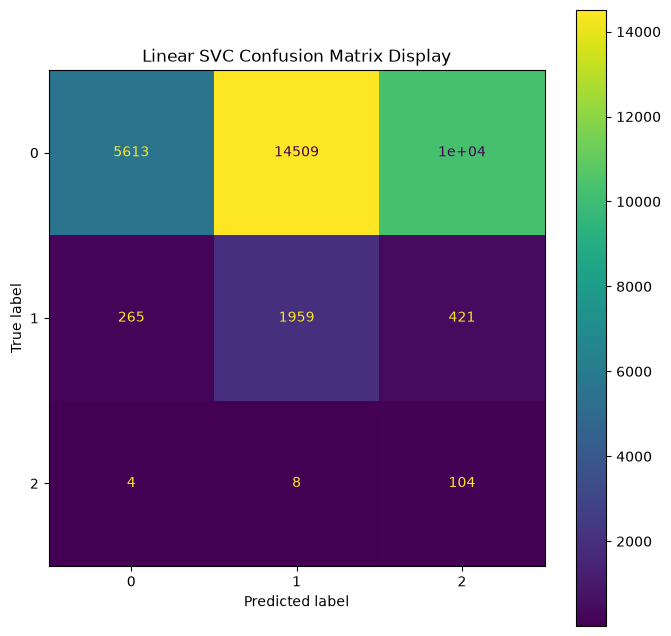

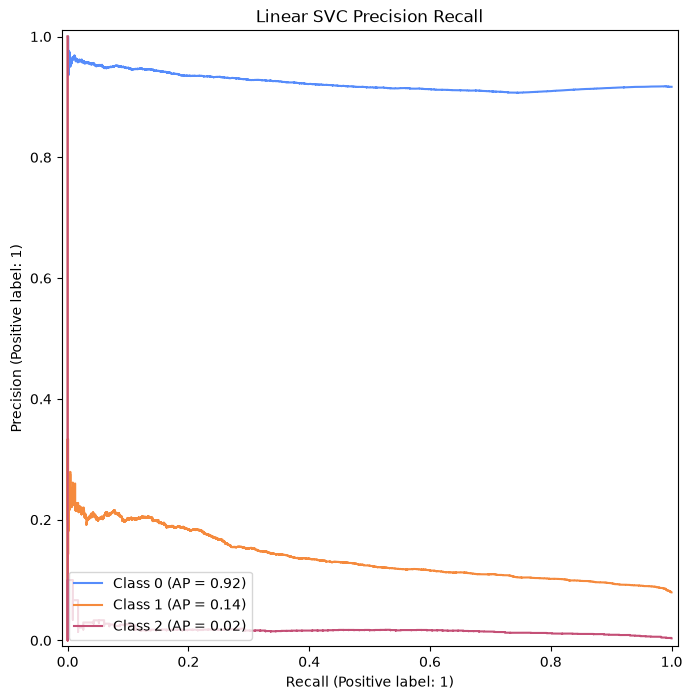

Macro Average Precision Score: 0.359


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during trans

Linear Discriminant Analysis Test Cross Val Accuracy: 0.4899 (0.0056)
Linear Discriminant Analysis Test Cross Val Balanced Accuracy: 0.6443 (0.0200)
Linear Discriminant Analysis Test Cross Val F1 Macro: 0.3047 (0.0042)
Linear Discriminant Analysis Test Cross Val ROC AUC: 0.7492 (0.0114)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.49      0.64     30407
           1       0.16      0.62      0.25      2645
           2       0.01      0.78      0.02       116

    accuracy                           0.50     33168
   macro avg       0.37      0.63      0.31     33168
weighted avg       0.89      0.50      0.61     33168

Confusion Matrix
[[14794  8684  6929]
 [  712  1645   288]
 [   20     6    90]]


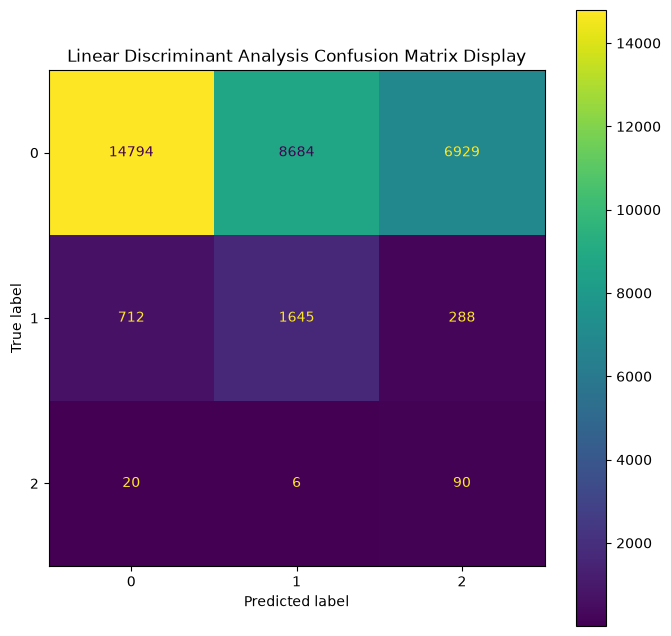

0 [0.66 0.6  0.61 ... 0.14 0.13 0.22]
1 [0.33 0.1  0.34 ... 0.86 0.86 0.75]
2 [0.01 0.3  0.05 ... 0.   0.   0.04]


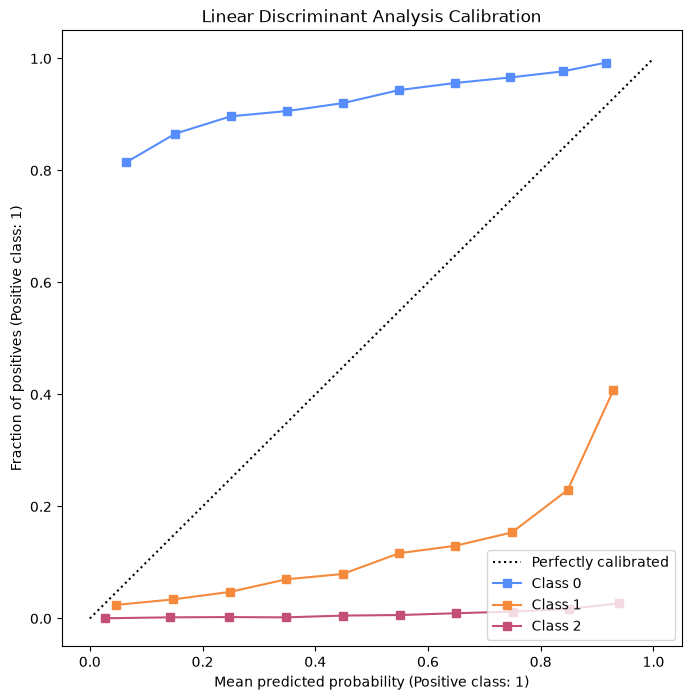

0 [0.66 0.6  0.61 ... 0.14 0.13 0.22]
1 [0.33 0.1  0.34 ... 0.86 0.86 0.75]
2 [0.01 0.3  0.05 ... 0.   0.   0.04]


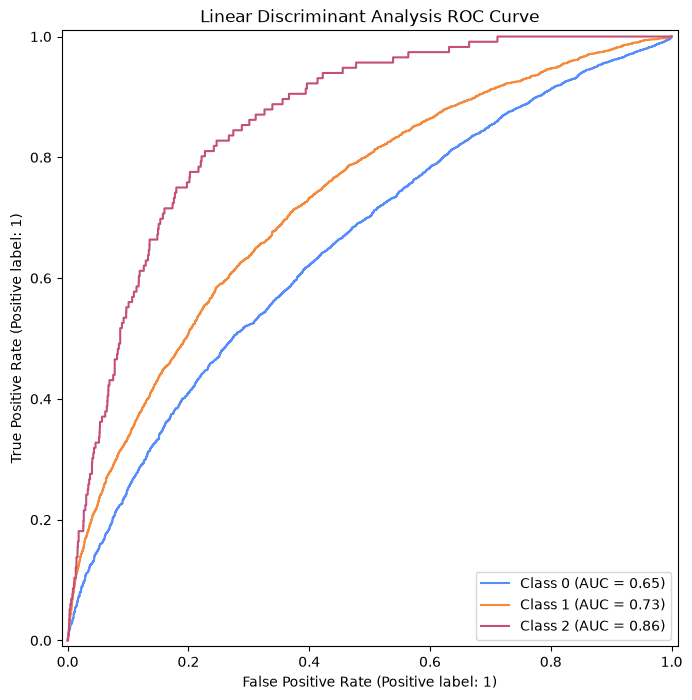

0 [0.66 0.6  0.61 ... 0.14 0.13 0.22]
1 [0.33 0.1  0.34 ... 0.86 0.86 0.75]
2 [0.01 0.3  0.05 ... 0.   0.   0.04]


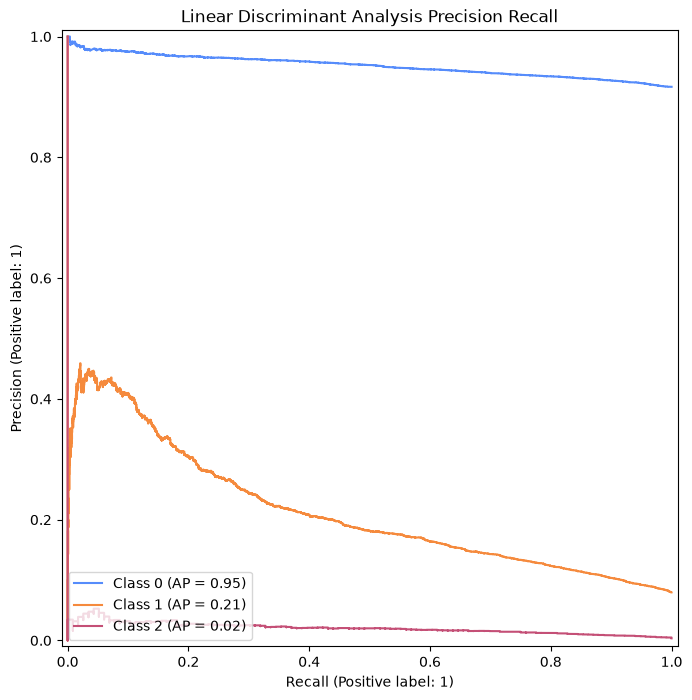

Macro Average Precision Score: 0.395


[Pipeline(memory=Memory(location=./model-cache/joblib),
          steps=[('continuous_data_transforms',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('box_cox',
                                                   PowerTransformer(method='box-cox',
                                                                    standardize=False),
                                                   [])],
                                    verbose_feature_names_out=False)),
                 ('drop_columns_transform',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('drop', 'drop',
                                                   ('E...
                                                                    VarianceThreshold()),
                                                                   ('recursive_feature_selection',
                                                    

In [8]:
primary_build_model_pipeline = _get_primary_build_model_pipeline()

primary_pipelines = run_model_pipeline(primary_build_model_pipeline, primary_x_train, primary_y_train,
                                       primary_x_test,
                                       primary_y_test)

primary_pipelines

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6595.22it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Log Regression Test Cross Val Accuracy: 0.4515 (0.0112)
Log Regression Test Cross Val Balanced Accuracy: 0.6374 (0.0039)
Log Regression Test Cross Val F1 Macro: 0.2878 (0.0049)
Log Regression Test Cross Val ROC AUC: 0.7416 (0.0071)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7181.91it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.42      0.58     11415
           1       0.15      0.65      0.24      1031
           2       0.01      0.86      0.02        42

    accuracy                           0.44     12488
   macro avg       0.37      0.64      0.28     12488
weighted avg       0.88      0.44      0.55     12488

Confusion Matrix
[[4800 3762 2853]
 [ 240  668  123]
 [   1    5   36]]


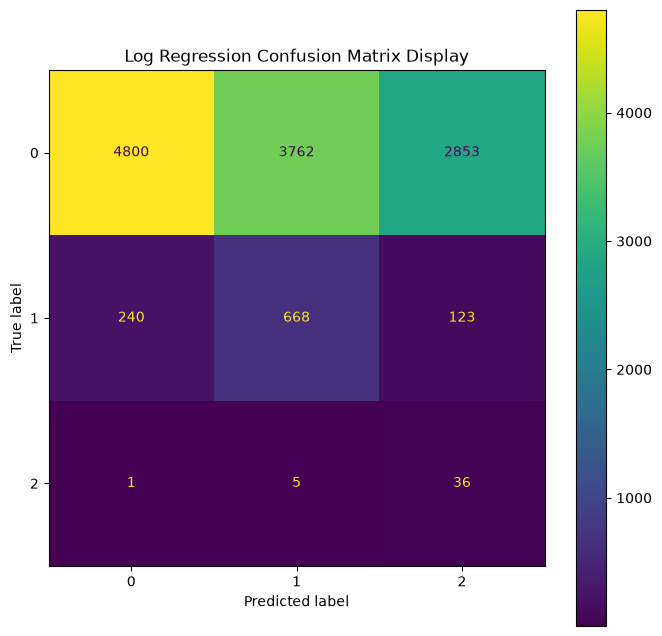

0 [0.83 0.21 0.24 ... 0.27 0.27 0.21]
1 [0.13 0.07 0.08 ... 0.65 0.71 0.72]
2 [0.04 0.72 0.68 ... 0.08 0.02 0.07]


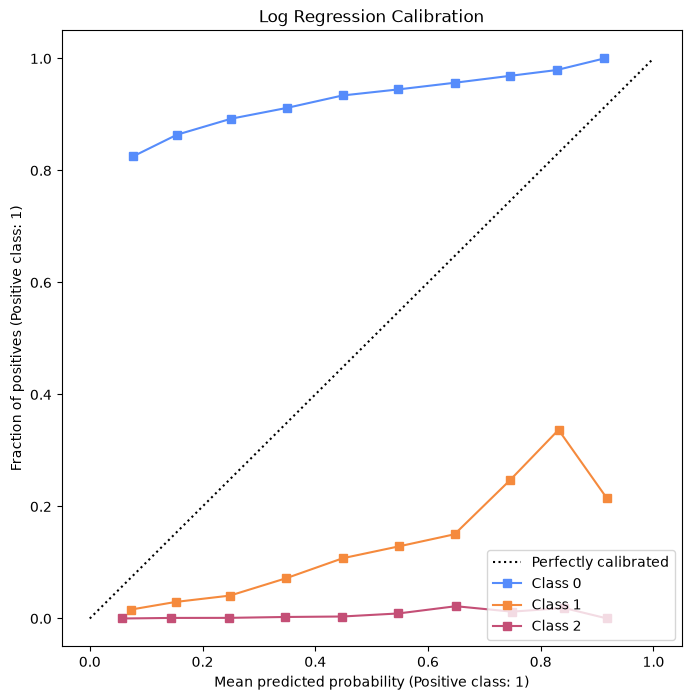

0 [0.83 0.21 0.24 ... 0.27 0.27 0.21]
1 [0.13 0.07 0.08 ... 0.65 0.71 0.72]
2 [0.04 0.72 0.68 ... 0.08 0.02 0.07]


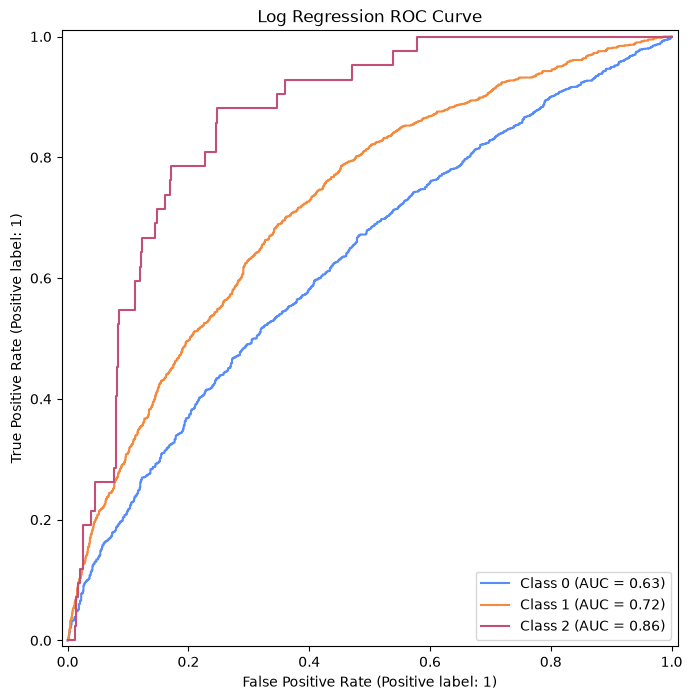

0 [0.83 0.21 0.24 ... 0.27 0.27 0.21]
1 [0.13 0.07 0.08 ... 0.65 0.71 0.72]
2 [0.04 0.72 0.68 ... 0.08 0.02 0.07]


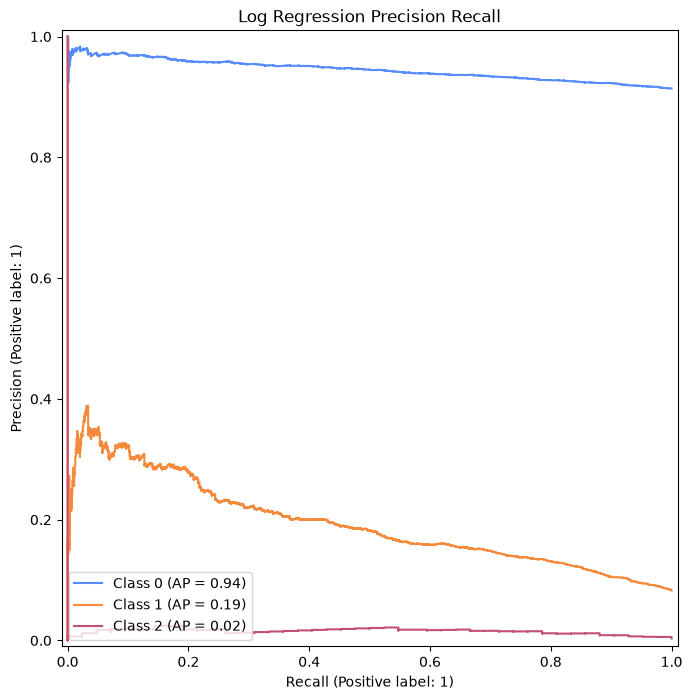

Macro Average Precision Score: 0.385


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7667.70it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

SGD Classifier Test Cross Val Accuracy: 0.4055 (0.0285)
SGD Classifier Test Cross Val Balanced Accuracy: 0.6429 (0.0156)
SGD Classifier Test Cross Val F1 Macro: 0.2638 (0.0148)
SGD Classifier Test Cross Val ROC AUC: 0.7363 (0.0171)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5285.21it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.55      0.69     11415
           1       0.17      0.59      0.26      1031
           2       0.01      0.79      0.03        42

    accuracy                           0.55     12488
   macro avg       0.38      0.64      0.33     12488
weighted avg       0.88      0.55      0.66     12488

Confusion Matrix
[[6244 3053 2118]
 [ 340  607   84]
 [   5    4   33]]


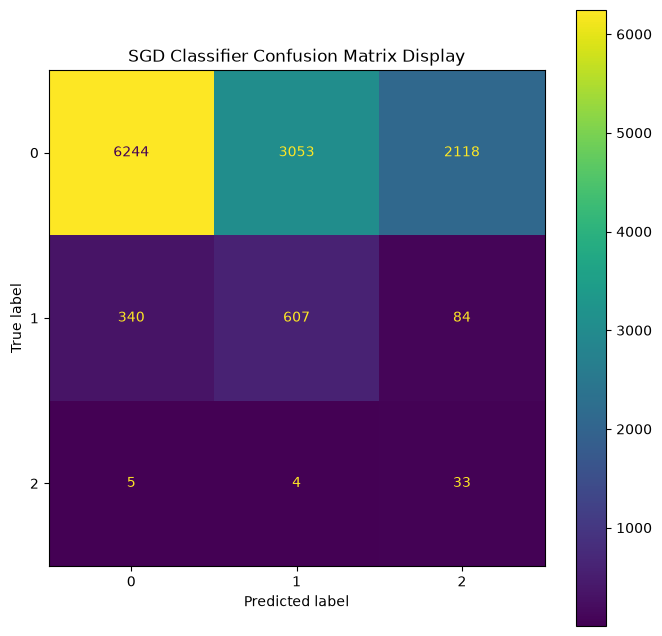

0 [0.73 0.33 0.35 ... 0.39 0.39 0.38]
1 [0.27 0.02 0.02 ... 0.61 0.61 0.62]
2 [9.35e-05 6.47e-01 6.23e-01 ... 1.76e-03 1.68e-04 5.14e-04]


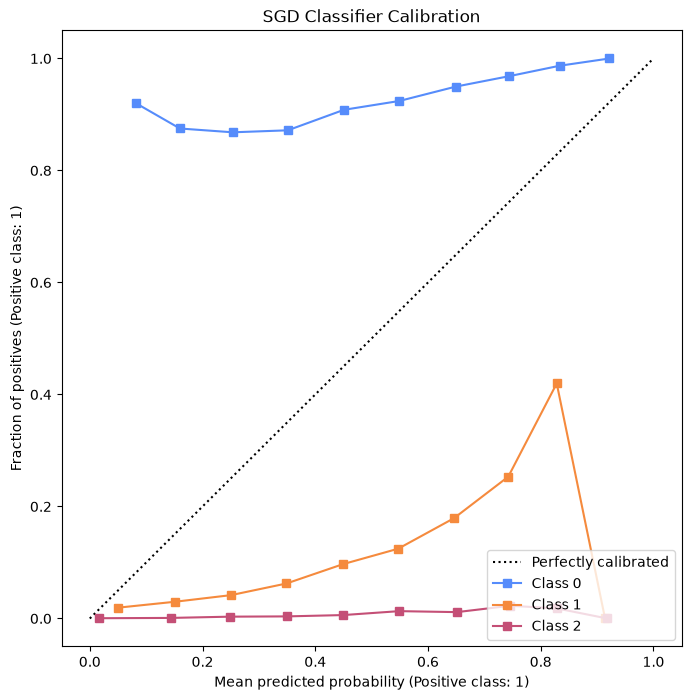

0 [0.73 0.33 0.35 ... 0.39 0.39 0.38]
1 [0.27 0.02 0.02 ... 0.61 0.61 0.62]
2 [9.35e-05 6.47e-01 6.23e-01 ... 1.76e-03 1.68e-04 5.14e-04]


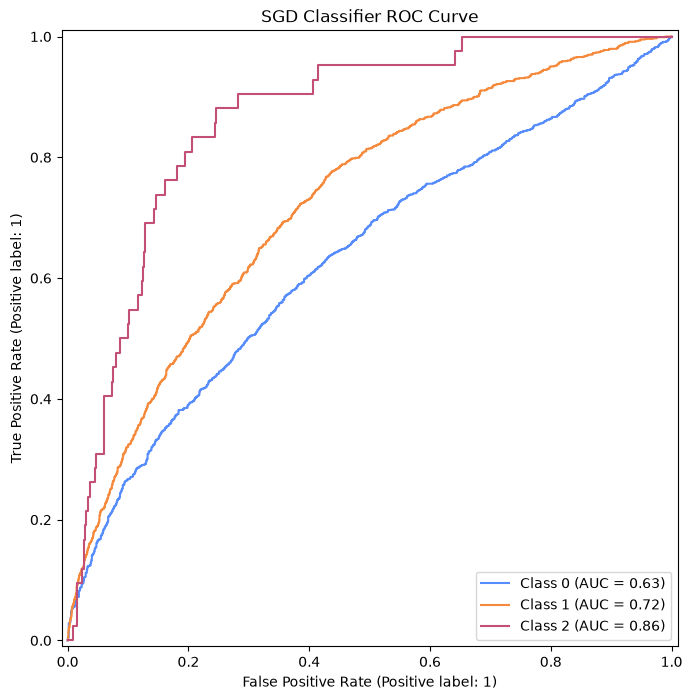

0 [0.73 0.33 0.35 ... 0.39 0.39 0.38]
1 [0.27 0.02 0.02 ... 0.61 0.61 0.62]
2 [9.35e-05 6.47e-01 6.23e-01 ... 1.76e-03 1.68e-04 5.14e-04]


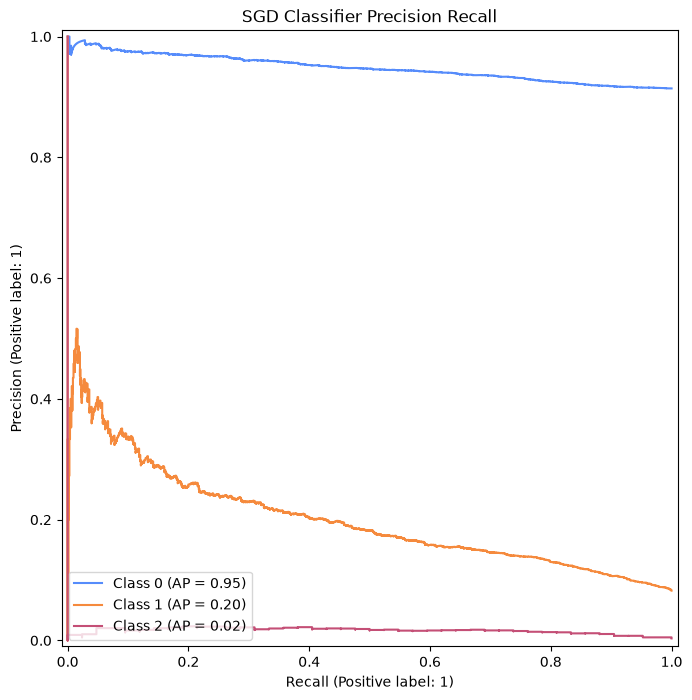

Macro Average Precision Score: 0.388


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2391.88it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

K-Neighbours Classifier Test Cross Val Accuracy: 0.7314 (0.0030)
K-Neighbours Classifier Test Cross Val Balanced Accuracy: 0.6188 (0.0185)
K-Neighbours Classifier Test Cross Val F1 Macro: 0.4148 (0.0018)
K-Neighbours Classifier Test Cross Val ROC AUC: 0.7683 (0.0078)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5553.01it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.76      0.85     11415
           1       0.23      0.74      0.36      1031
           2       0.07      0.48      0.12        42

    accuracy                           0.76     12488
   macro avg       0.42      0.66      0.44     12488
weighted avg       0.91      0.76      0.81     12488

Confusion Matrix
[[8649 2499  267]
 [ 261  764    6]
 [  16    6   20]]


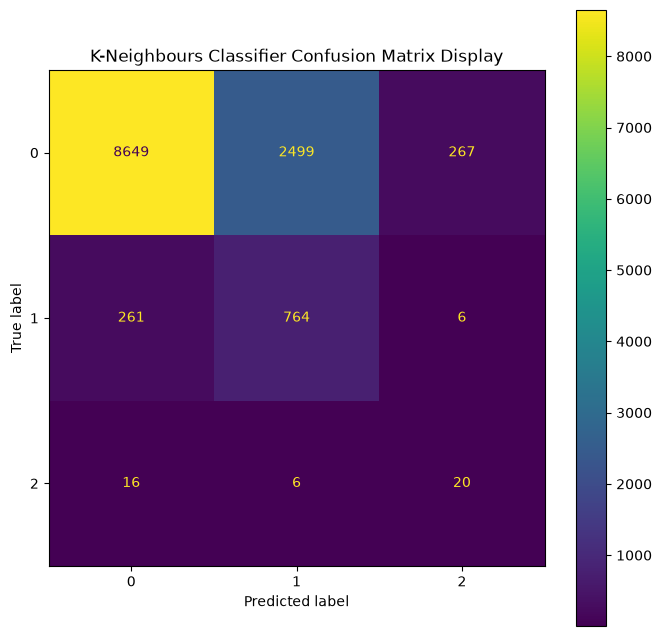

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


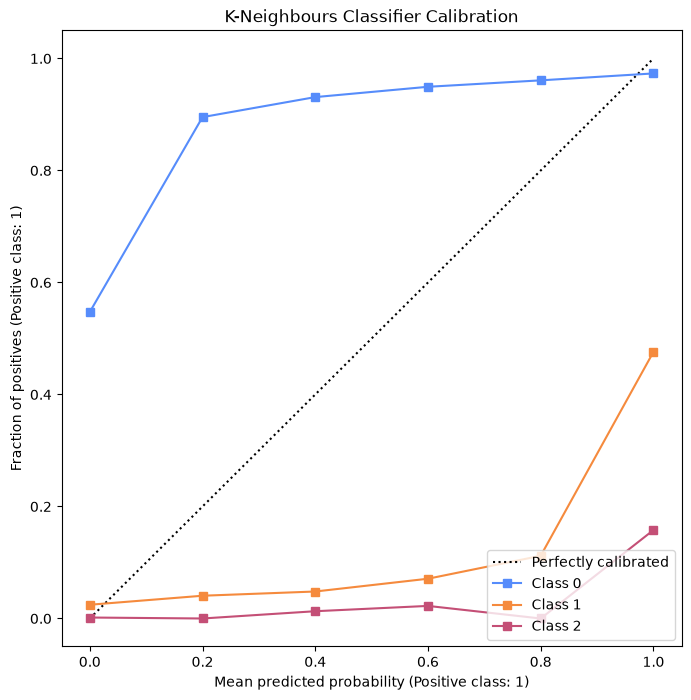

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


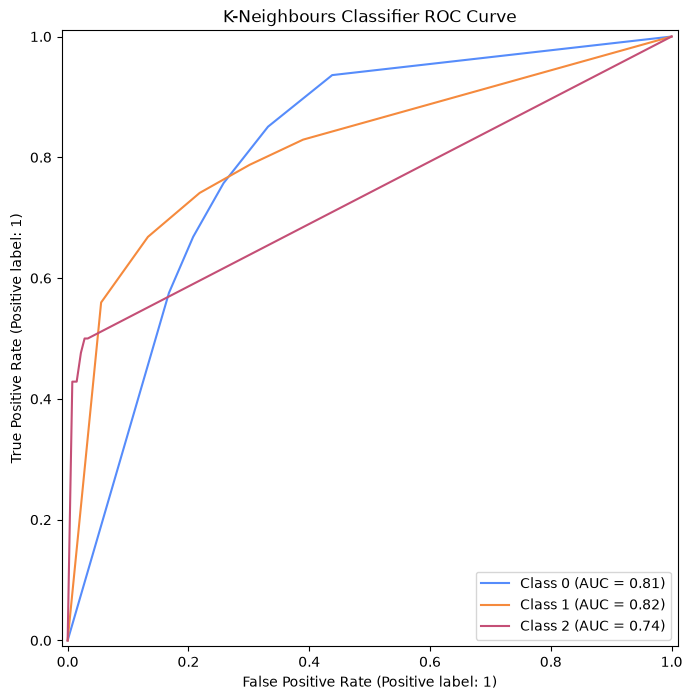

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


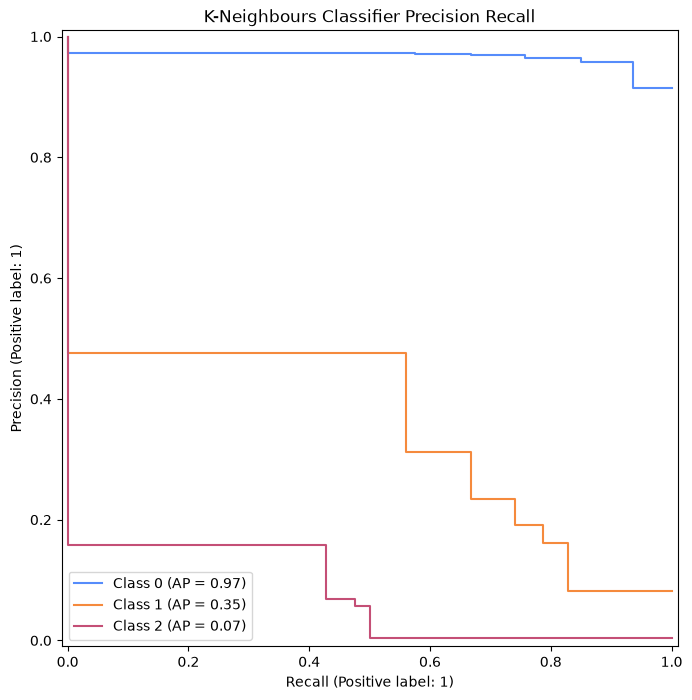

Macro Average Precision Score: 0.463


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7247.57it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Decision Tree Classifier Test Cross Val Accuracy: 0.5550 (0.1188)
Decision Tree Classifier Test Cross Val Balanced Accuracy: 0.5073 (0.0097)
Decision Tree Classifier Test Cross Val F1 Macro: 0.3158 (0.0459)
Decision Tree Classifier Test Cross Val ROC AUC: 0.6599 (0.0145)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.74      0.83     11415
           1       0.19      0.58      0.29      1031
           2       0.04      0.40      0.07        42

    accuracy                           0.73     12488
   macro avg       0.39      0.58      0.40     12488
weighted avg       0.89      0.73      0.79     12488

Confusion Matrix
[[8451 2533  431]
 [ 413  602   16]
 [  17    8   17]]


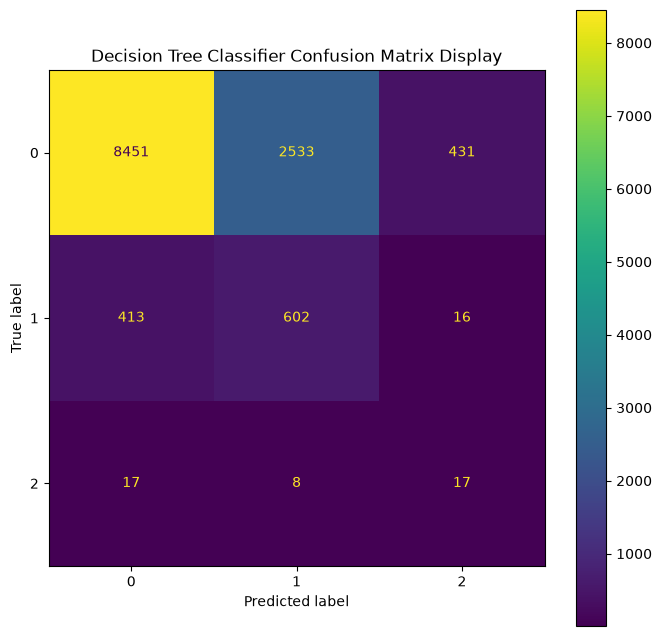

0 [0.43 0.13 1.   ... 0.88 0.4  0.67]
1 [0.57 0.   0.   ... 0.12 0.6  0.33]
2 [0.   0.87 0.   ... 0.   0.   0.  ]


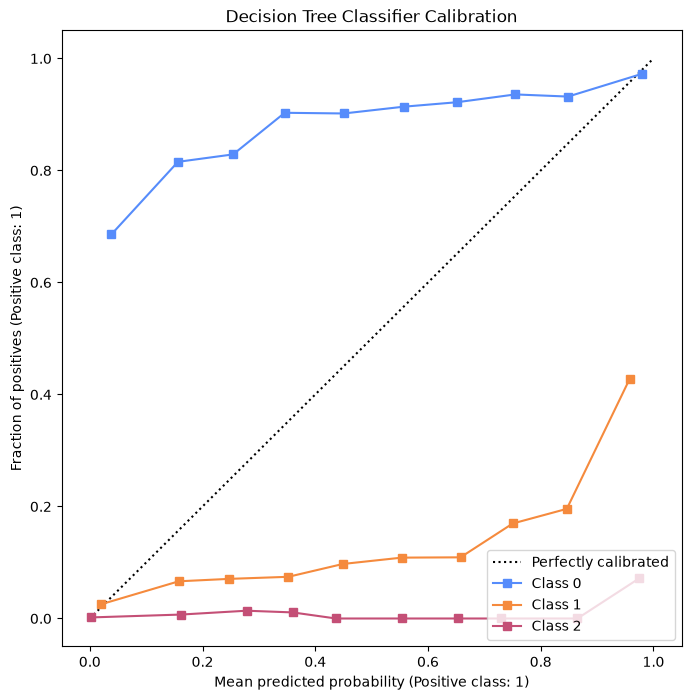

0 [0.43 0.13 1.   ... 0.88 0.4  0.67]
1 [0.57 0.   0.   ... 0.12 0.6  0.33]
2 [0.   0.87 0.   ... 0.   0.   0.  ]


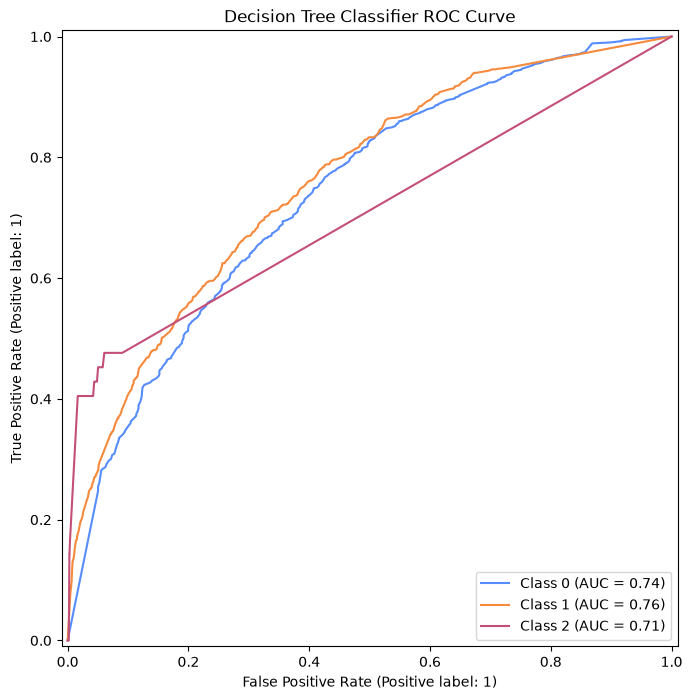

0 [0.43 0.13 1.   ... 0.88 0.4  0.67]
1 [0.57 0.   0.   ... 0.12 0.6  0.33]
2 [0.   0.87 0.   ... 0.   0.   0.  ]


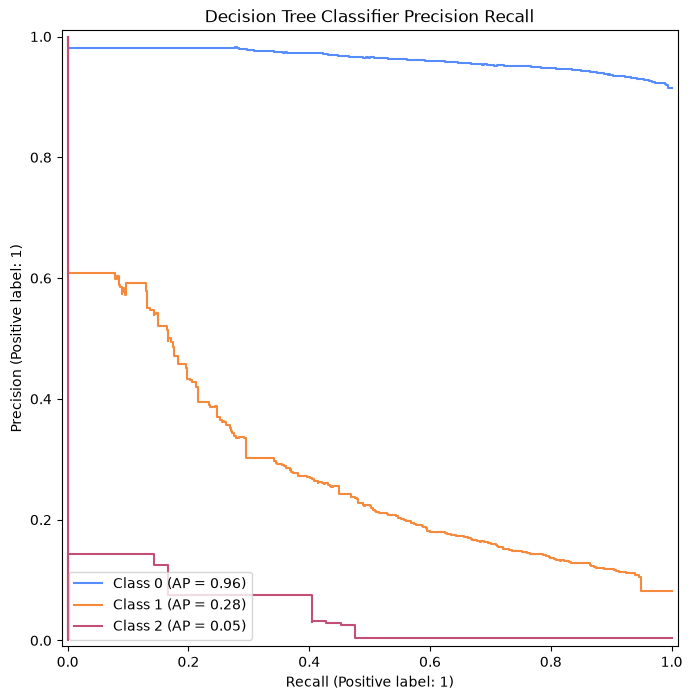

Macro Average Precision Score: 0.429


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Linear SVC Test Cross Val Accuracy: 0.1234 (0.0182)
Linear SVC Test Cross Val Balanced Accuracy: 0.5752 (0.0292)
Linear SVC Test Cross Val F1 Macro: 0.1035 (0.0140)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.96      0.11      0.19     11415
           1       0.11      0.83      0.19      1031
           2       0.01      0.81      0.02        42

    accuracy                           0.17     12488
   macro avg       0.36      0.58      0.13     12488
weighted avg       0.88      0.17      0.19     12488

Confusion Matrix
[[1209 7226 2980]
 [  51  857  123]
 [   2    6   34]]


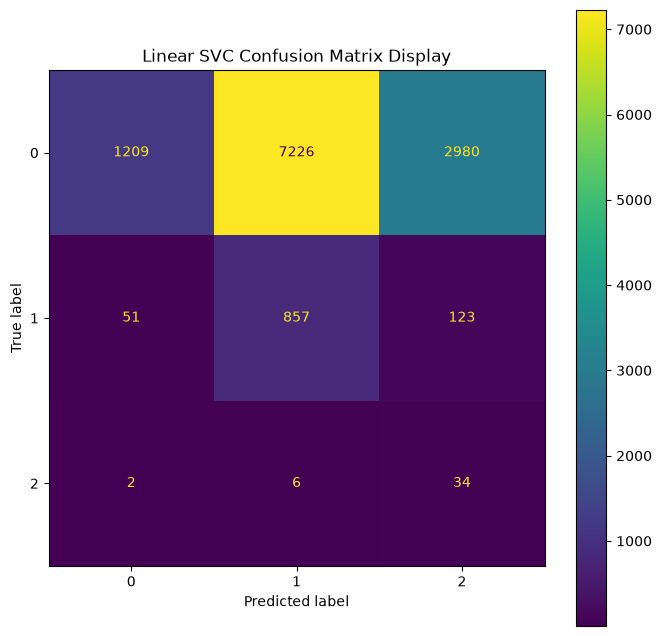

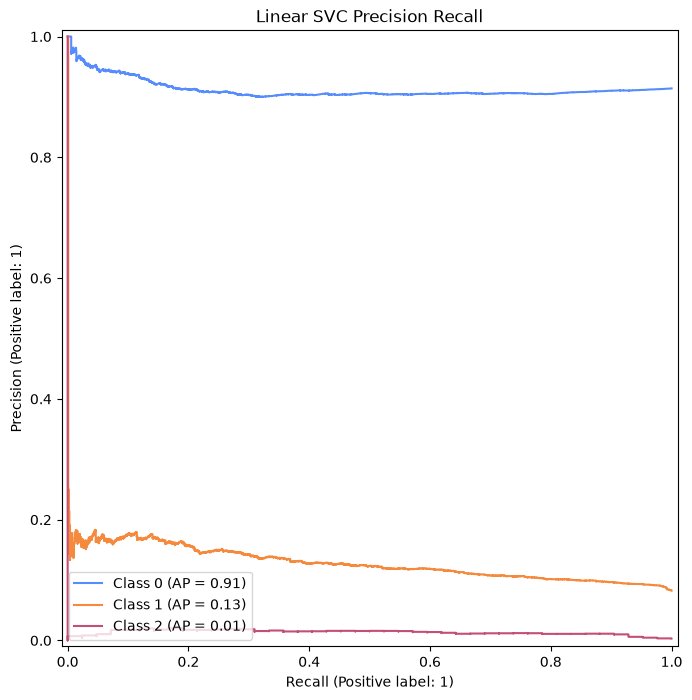

Macro Average Precision Score: 0.352


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Linear Discriminant Analysis Test Cross Val Accuracy: 0.5066 (0.0110)
Linear Discriminant Analysis Test Cross Val Balanced Accuracy: 0.6372 (0.0012)
Linear Discriminant Analysis Test Cross Val F1 Macro: 0.3084 (0.0048)
Linear Discriminant Analysis Test Cross Val ROC AUC: 0.7376 (0.0095)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.48      0.64     11415
           1       0.16      0.65      0.26      1031
           2       0.01      0.81      0.03        42

    accuracy                           0.50     12488
   macro avg       0.37      0.65      0.31     12488
weighted avg       0.88      0.50      0.61     12488

Confusion Matrix
[[5531 3512 2372]
 [ 278  666   87]
 [   6    2   34]]


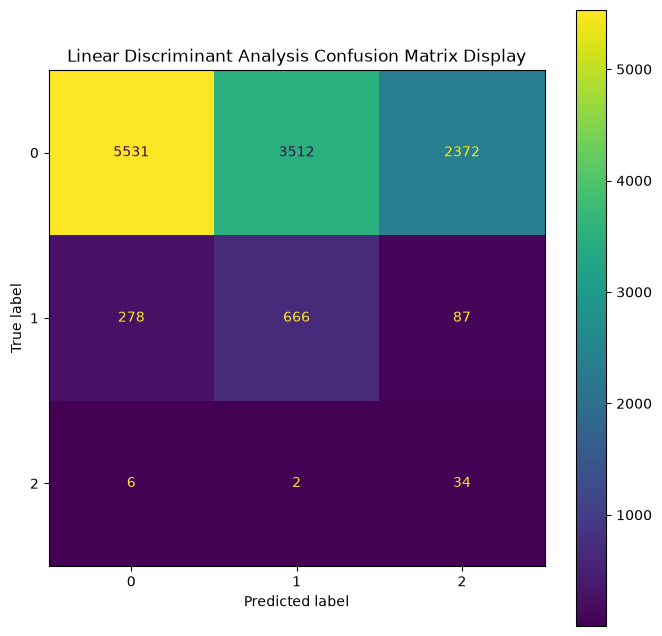

0 [0.83 0.1  0.13 ... 0.28 0.16 0.21]
1 [0.17 0.01 0.01 ... 0.72 0.84 0.79]
2 [1.25e-03 8.94e-01 8.52e-01 ... 2.30e-03 1.18e-04 2.80e-03]


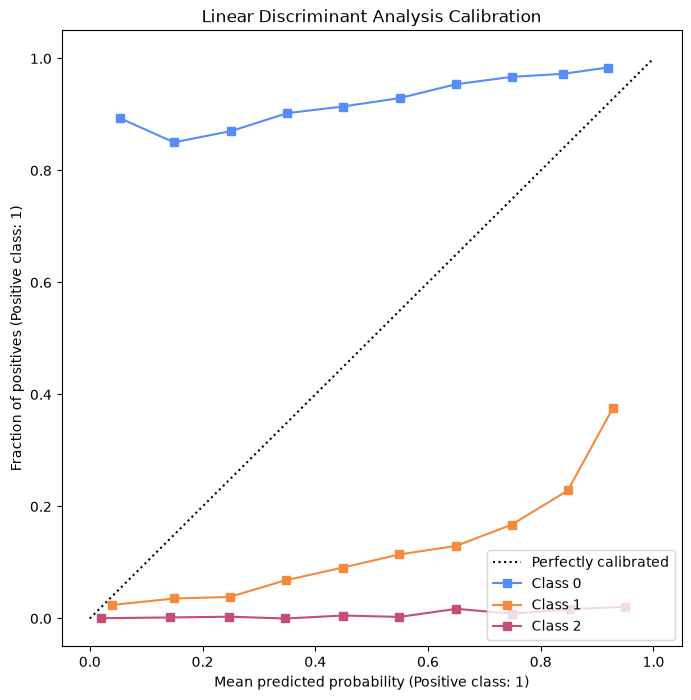

0 [0.83 0.1  0.13 ... 0.28 0.16 0.21]
1 [0.17 0.01 0.01 ... 0.72 0.84 0.79]
2 [1.25e-03 8.94e-01 8.52e-01 ... 2.30e-03 1.18e-04 2.80e-03]


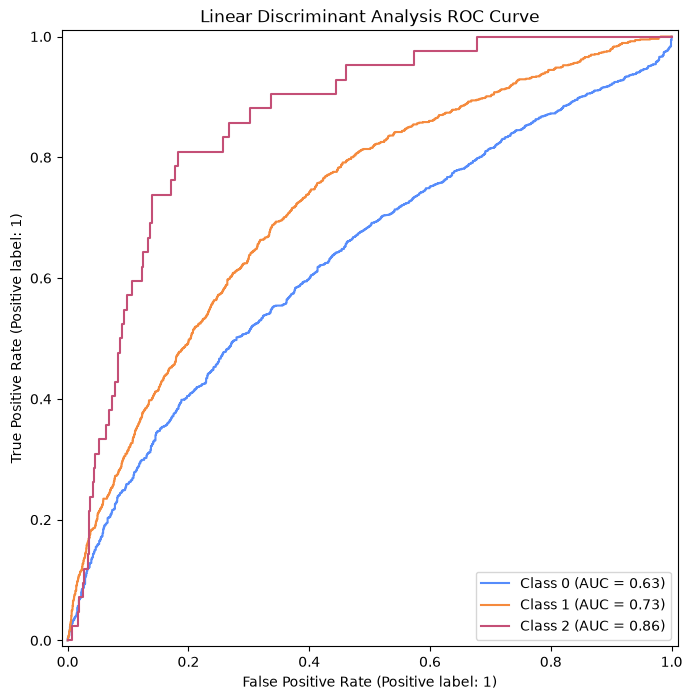

0 [0.83 0.1  0.13 ... 0.28 0.16 0.21]
1 [0.17 0.01 0.01 ... 0.72 0.84 0.79]
2 [1.25e-03 8.94e-01 8.52e-01 ... 2.30e-03 1.18e-04 2.80e-03]


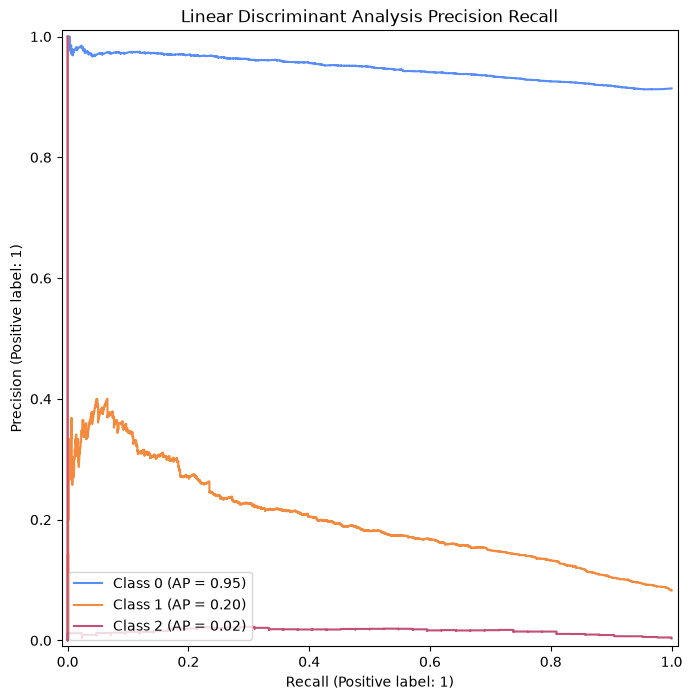

Macro Average Precision Score: 0.388


[Pipeline(memory=Memory(location=./model-cache/joblib),
          steps=[('continuous_data_transforms',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('box_cox',
                                                   PowerTransformer(method='box-cox',
                                                                    standardize=False),
                                                   ('Floor Area (m^2)',))],
                                    verbose_feature_names_out=False)),
                 ('drop_columns_transform',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[(...
                                                                    VarianceThreshold()),
                                                                   ('recursive_feature_selection',
                                                                    RFE(estimator=LogisticRegression(cl

In [4]:
physical_build_model_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                         X_ORDINAL_ENCODED_CATEGORIES,
                                                         HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                         LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipelines = run_model_pipeline(physical_build_model_pipeline, physical_x_train, physical_y_train,
                                        physical_x_test,
                                        physical_y_test)

physical_pipelines

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19966.41it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

K-Neighbours Bagging Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                   verbose_feature_names_out=False)),
                ('target_resampling

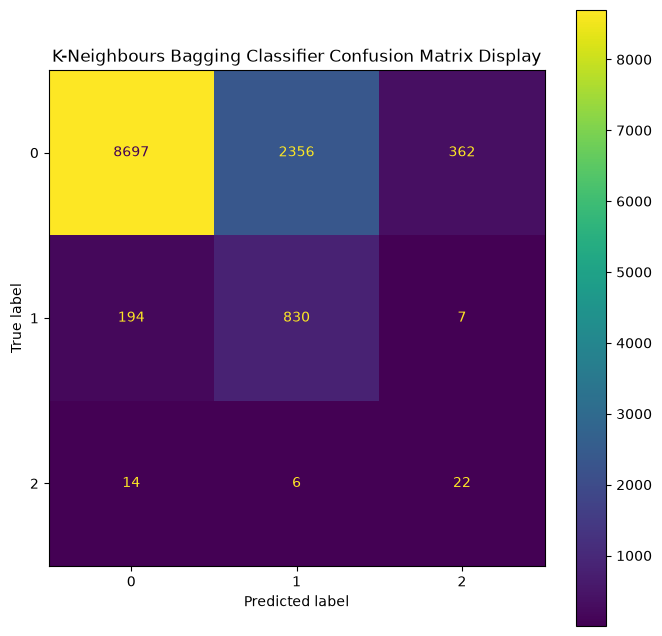

0 [1.   0.85 0.64 ... 0.27 0.87 0.67]
1 [0.   0.   0.28 ... 0.73 0.13 0.33]
2 [0.   0.15 0.07 ... 0.   0.   0.  ]


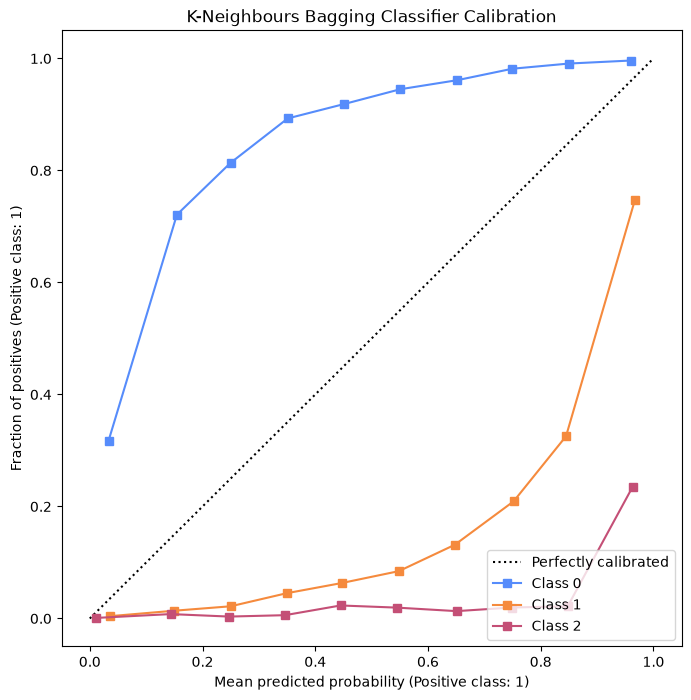

0 [1.   0.85 0.64 ... 0.27 0.87 0.67]
1 [0.   0.   0.28 ... 0.73 0.13 0.33]
2 [0.   0.15 0.07 ... 0.   0.   0.  ]


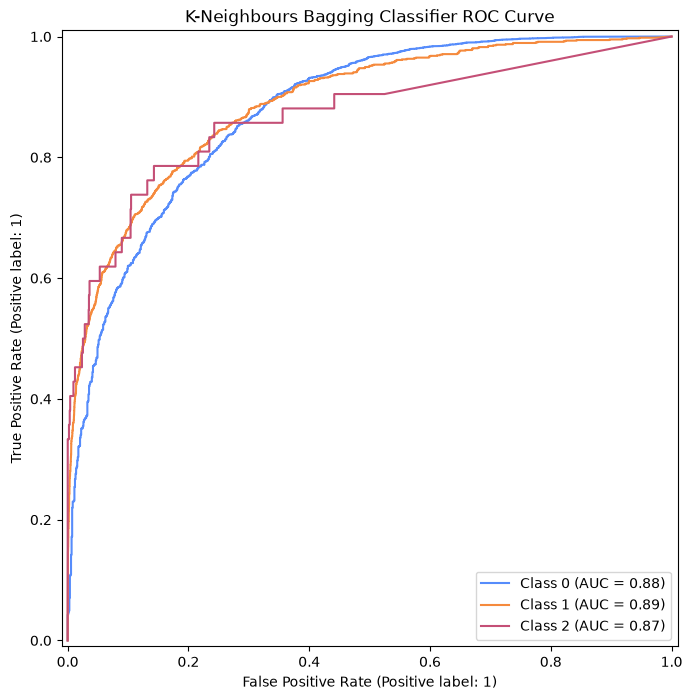

0 [1.   0.85 0.64 ... 0.27 0.87 0.67]
1 [0.   0.   0.28 ... 0.73 0.13 0.33]
2 [0.   0.15 0.07 ... 0.   0.   0.  ]


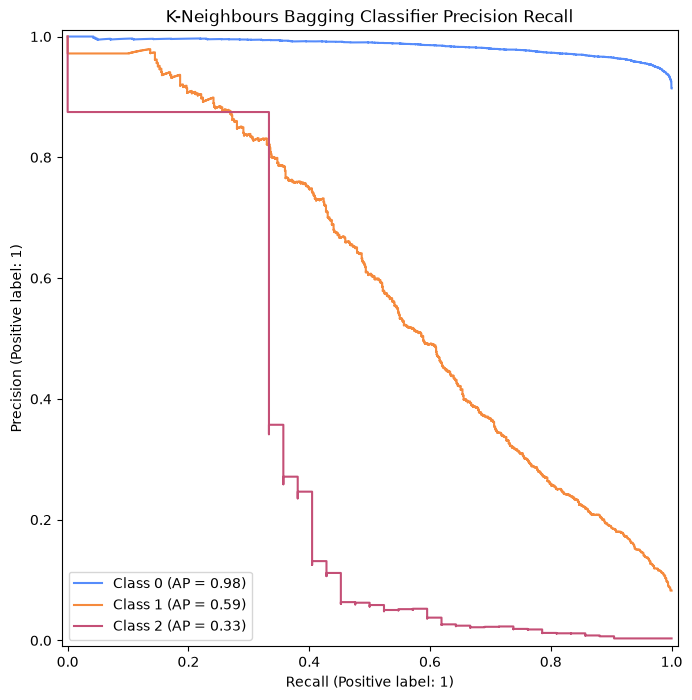

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [7]:
gc.collect()
torch.cuda.empty_cache()

physical_kneighbours_bagging_classifier_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                                            X_ORDINAL_ENCODED_CATEGORIES,
                                                                            HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                                            LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_kneighbours_bagging_classifier_pipeline(physical_kneighbours_bagging_classifier_pipeline,
                                                                physical_x_train,
                                                                physical_y_train,
                                                                physical_x_test,
                                                                physical_y_test)

physical_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6948.68it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Random Forest Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                                  slice(None, None, None))],
                                   

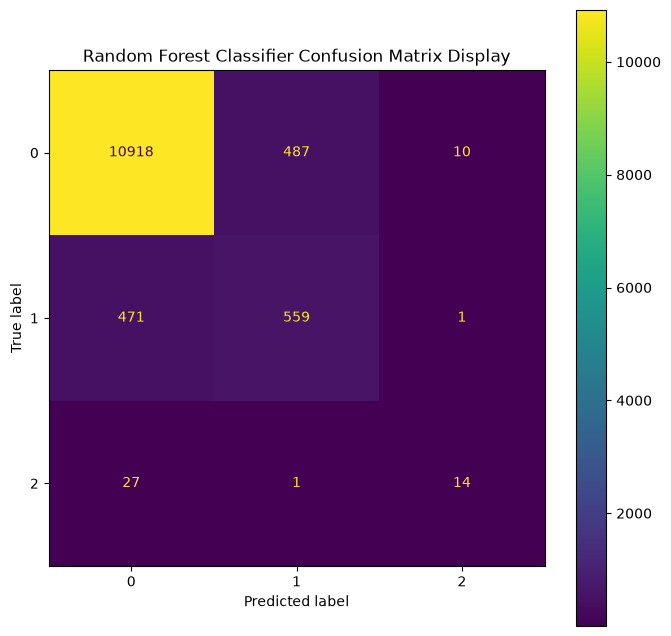

0 [0.96 0.83 0.76 ... 0.6  0.76 0.67]
1 [0.04 0.08 0.08 ... 0.4  0.24 0.33]
2 [0.   0.09 0.16 ... 0.   0.   0.  ]


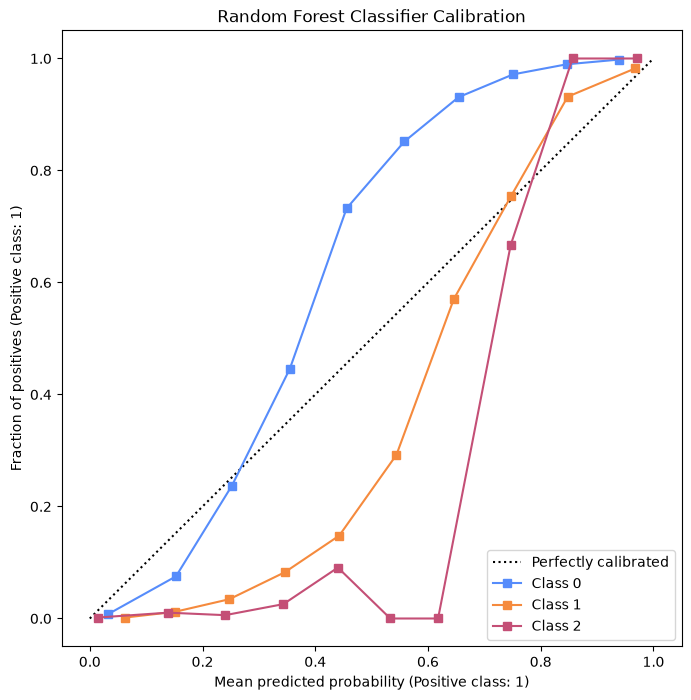

0 [0.96 0.83 0.76 ... 0.6  0.76 0.67]
1 [0.04 0.08 0.08 ... 0.4  0.24 0.33]
2 [0.   0.09 0.16 ... 0.   0.   0.  ]


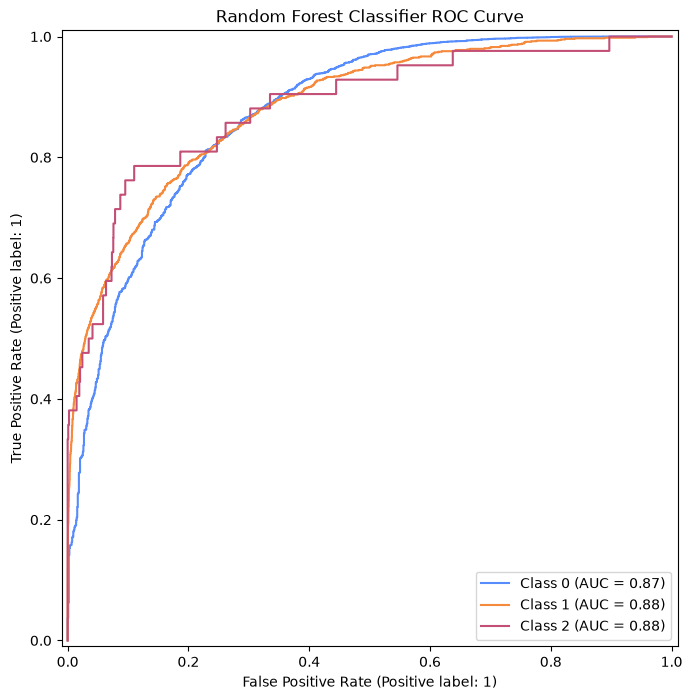

0 [0.96 0.83 0.76 ... 0.6  0.76 0.67]
1 [0.04 0.08 0.08 ... 0.4  0.24 0.33]
2 [0.   0.09 0.16 ... 0.   0.   0.  ]


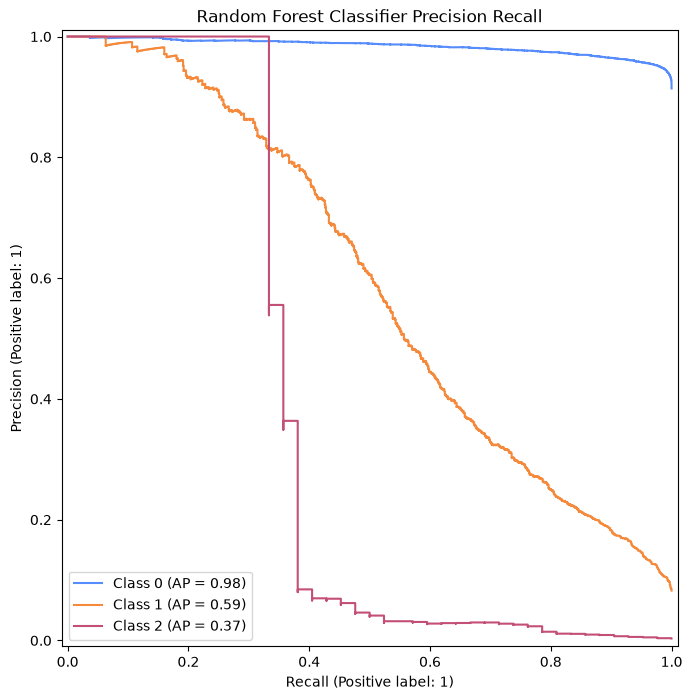

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [8]:
gc.collect()
torch.cuda.empty_cache()

random_forest_classifier_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                             X_ORDINAL_ENCODED_CATEGORIES,
                                                             HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                             LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_random_forest_pipeline(random_forest_classifier_pipeline, physical_x_train,
                                               physical_y_train,
                                               physical_x_test,
                                               physical_y_test)

physical_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6688.76it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

ADA Boost Decision Tree Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                                                                                    ma

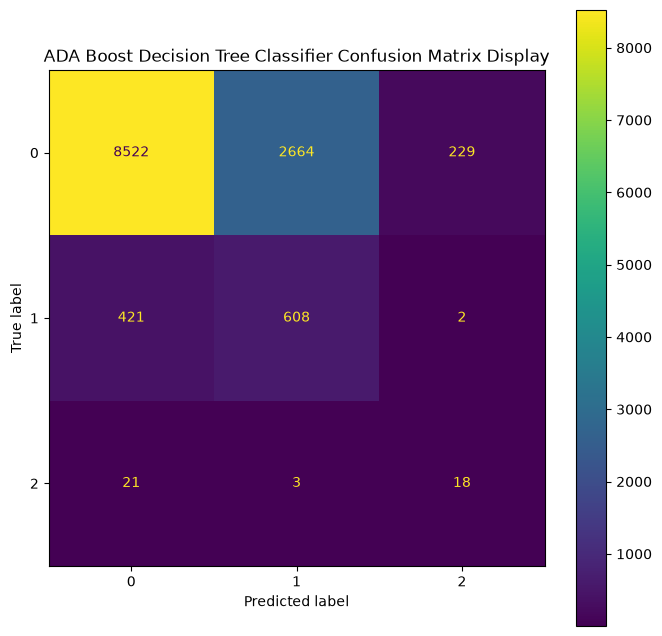

0 [0.39 0.36 0.34 ... 0.37 0.37 0.37]
1 [0.35 0.32 0.33 ... 0.37 0.37 0.37]
2 [0.26 0.33 0.33 ... 0.26 0.26 0.26]


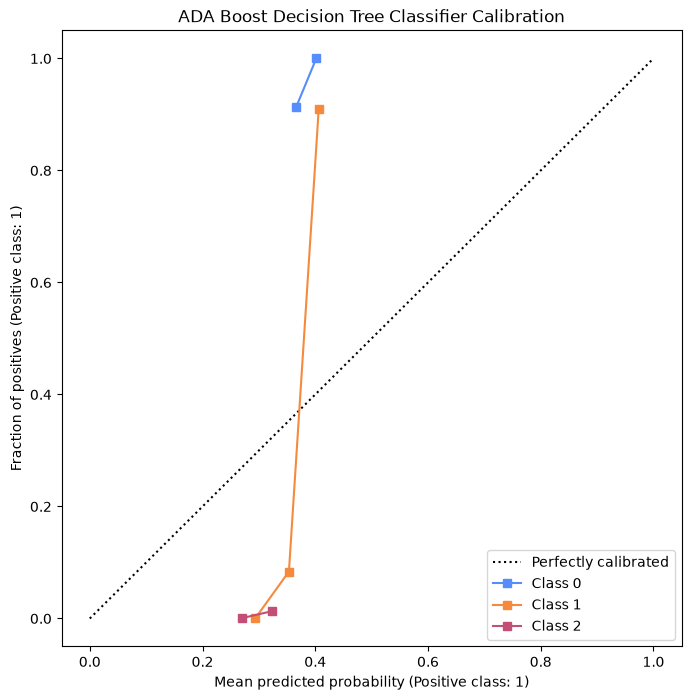

0 [0.39 0.36 0.34 ... 0.37 0.37 0.37]
1 [0.35 0.32 0.33 ... 0.37 0.37 0.37]
2 [0.26 0.33 0.33 ... 0.26 0.26 0.26]


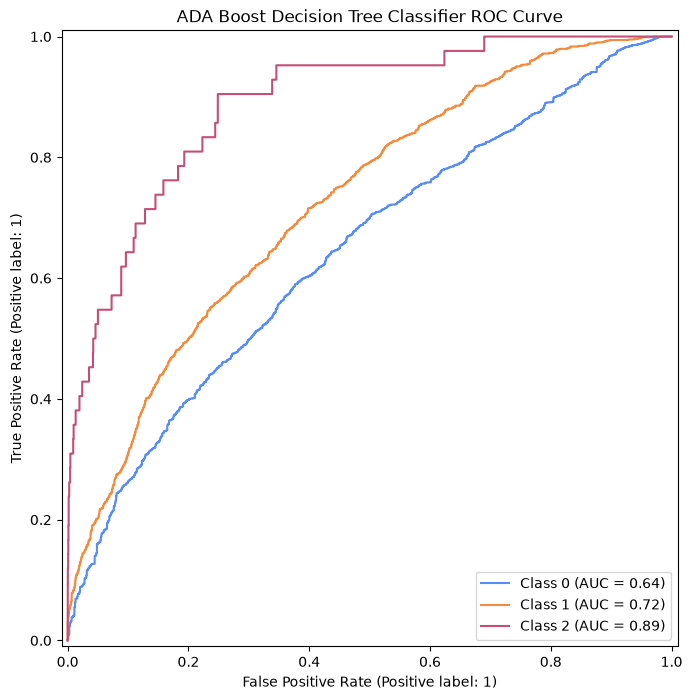

0 [0.39 0.36 0.34 ... 0.37 0.37 0.37]
1 [0.35 0.32 0.33 ... 0.37 0.37 0.37]
2 [0.26 0.33 0.33 ... 0.26 0.26 0.26]


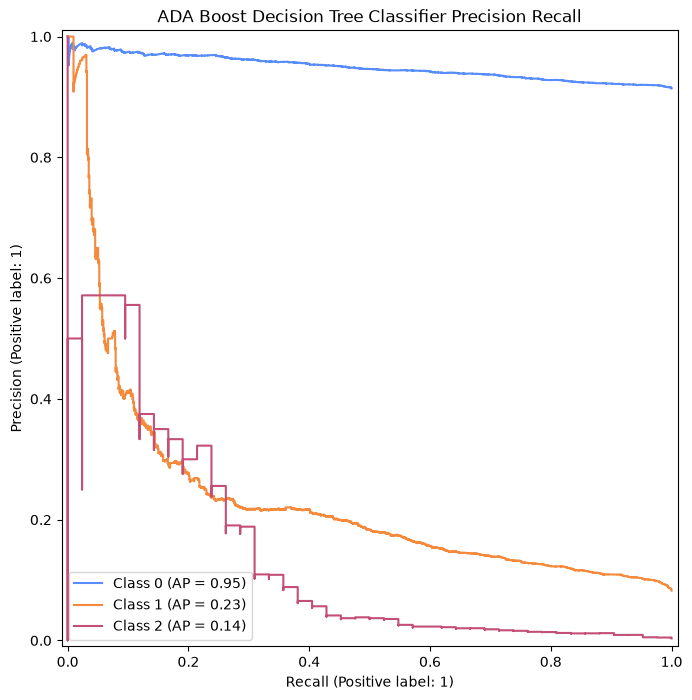

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [9]:
gc.collect()
torch.cuda.empty_cache()

physical_adaboost_decision_tree_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                                    X_ORDINAL_ENCODED_CATEGORIES,
                                                                    HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                                    LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_adaboost_decision_tree_pipeline(physical_adaboost_decision_tree_pipeline,
                                                        physical_x_train,
                                                        physical_y_train,
                                                        physical_x_test,
                                                        physical_y_test)

physical_pipeline

In [10]:
print(primary_y_train[INFERRED_TARGET_FIELD].value_counts())
print(physical_y_train[INFERRED_TARGET_FIELD].value_counts())

k_neighbours_estimator: RandomizedSearchCV = joblib.load(BAGGING_CLASSIFIER_KNEIGHBOURS_DUMP)

Inferred Planning Decision
0    61734
1     5370
2      237
Name: count, dtype: int64
Inferred Planning Decision
0    23024
1     2103
2       77
Name: count, dtype: int64


PermutationExplainer explainer: 51it [1:31:31, 109.82s/it]                        

SHAP explanation for class: Approve


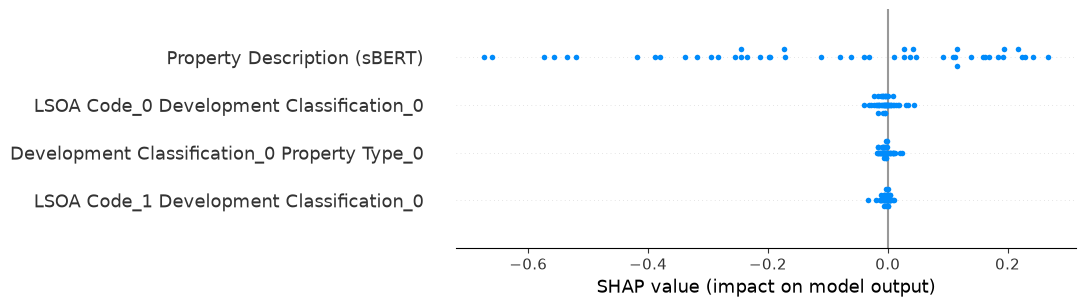

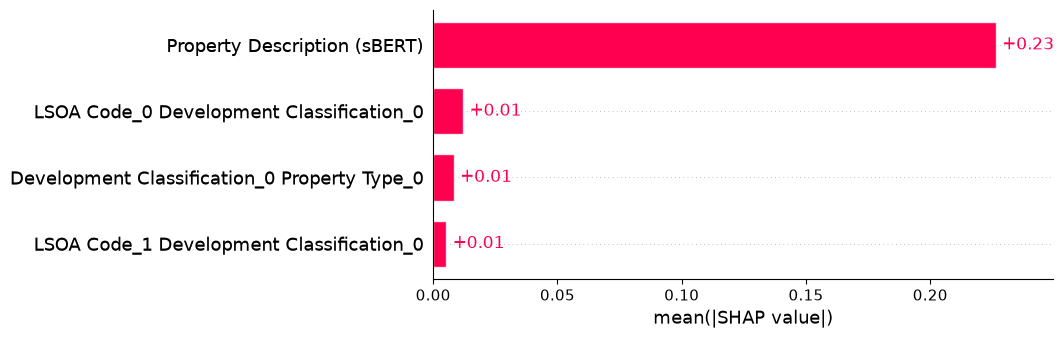

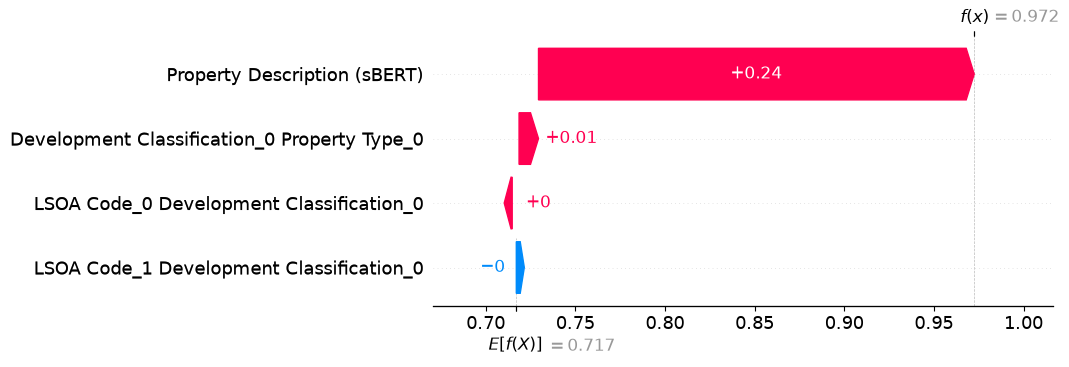

SHAP explanation for class: Refuse


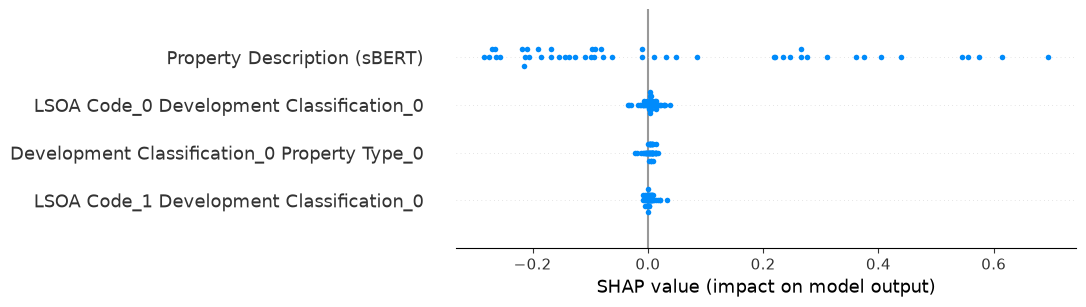

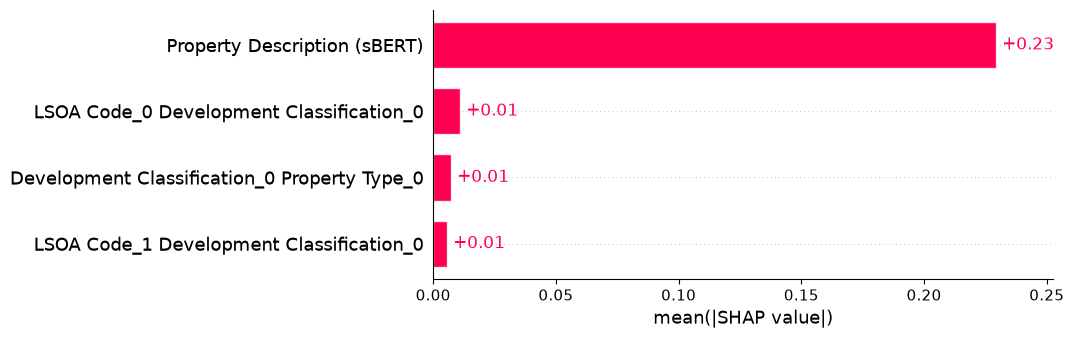

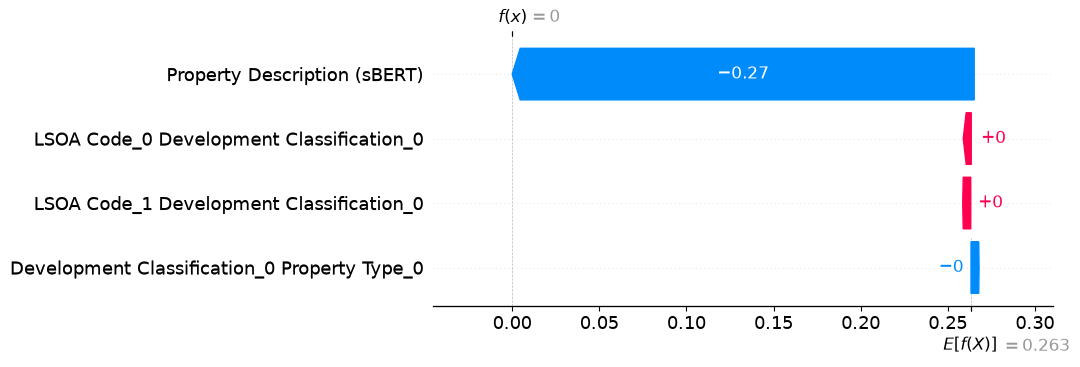

SHAP explanation for class: Split


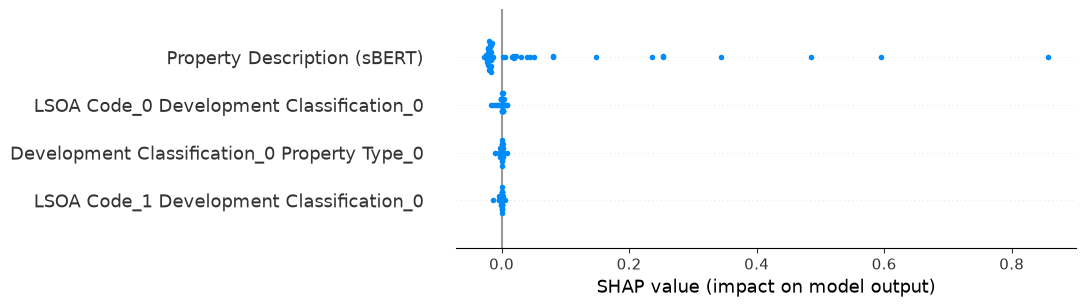

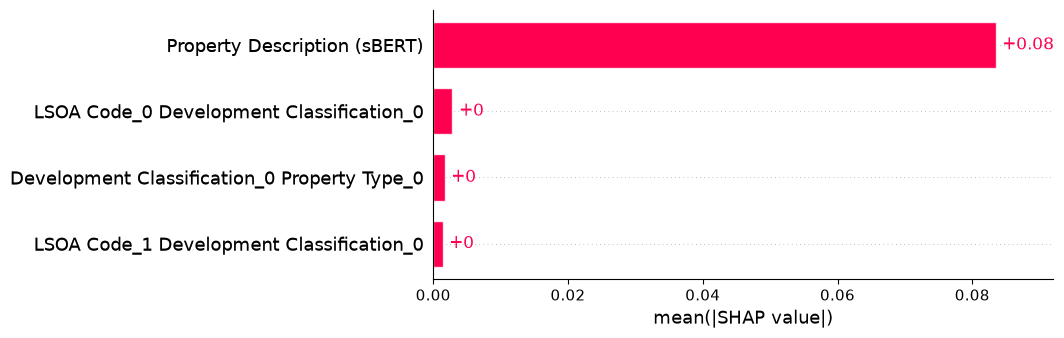

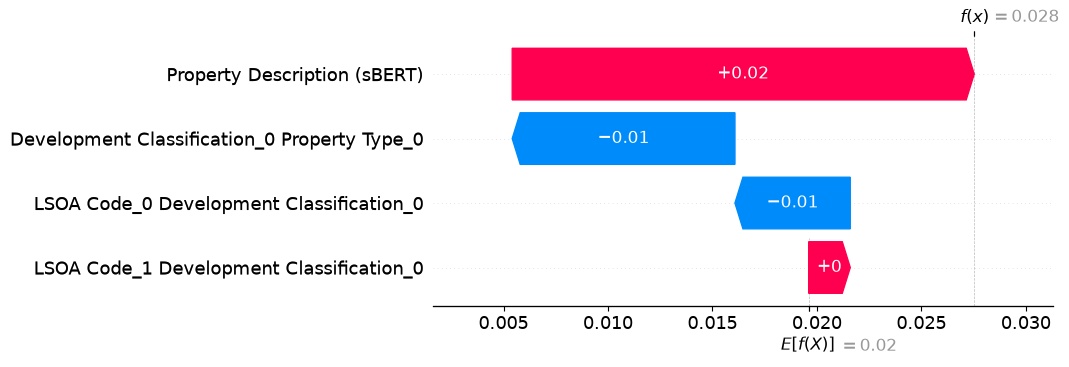

In [11]:
run_shap_analysis(k_neighbours_estimator.best_estimator_, physical_x_train, physical_x_test)

                 total  errors  error_rate  error_rate_pct
confidence_band                                           
(0.499, 0.6]      2430     992    0.408230       40.823045
(0.6, 0.7]        2407     814    0.338180       33.818031
(0.7, 0.8]        2282     460    0.201578       20.157756
(0.8, 0.9]        2202     318    0.144414       14.441417
(0.9, 1.0]        2835     201    0.070899        7.089947


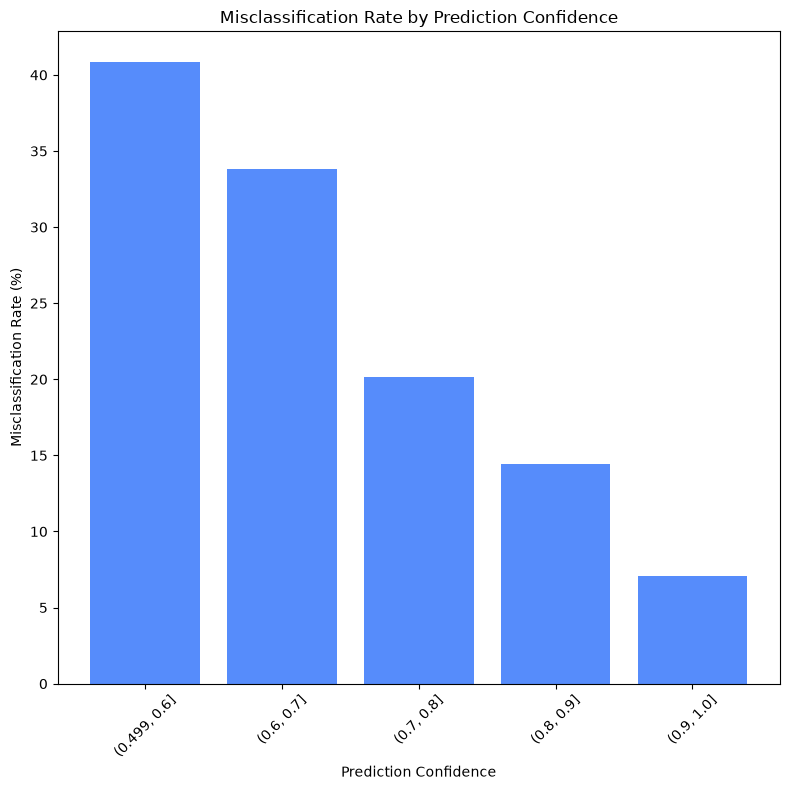

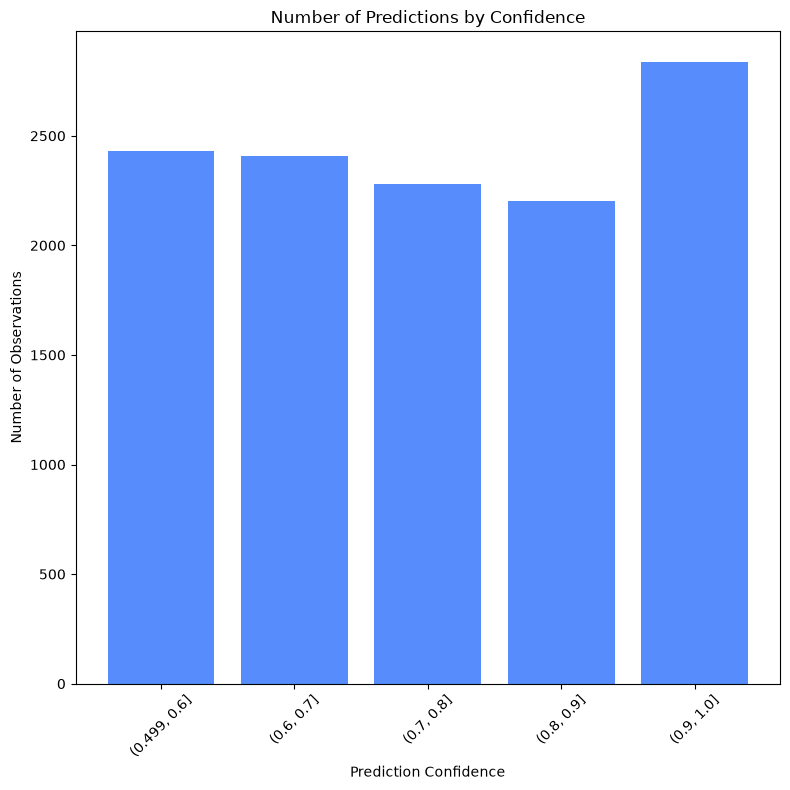

In [13]:
run_shap_inconsistency_analysis(k_neighbours_estimator.best_estimator_, physical_x_test, physical_y_test)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11865.24it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

K-Neighbours Bagging Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                   verbose_feature_names_out=False)),
                ('target_resamplin

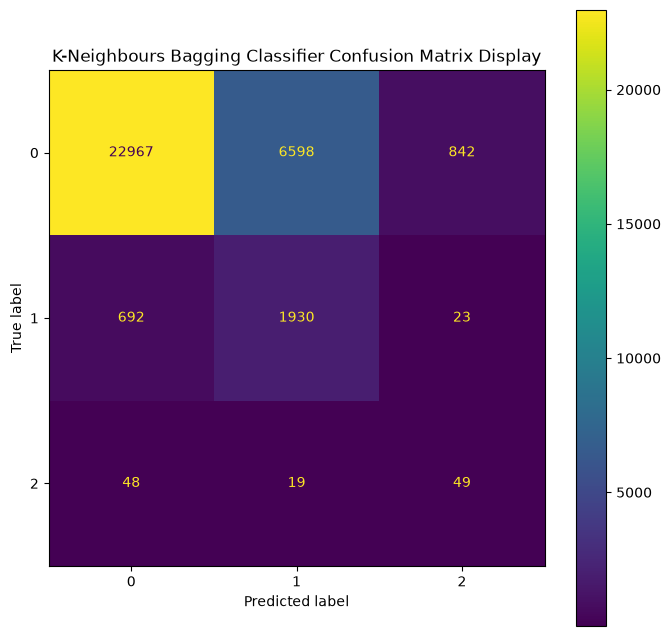

0 [0.9  0.99 0.42 ... 0.64 0.83 0.49]
1 [0.09 0.   0.58 ... 0.36 0.17 0.47]
2 [0.   0.01 0.   ... 0.   0.   0.04]


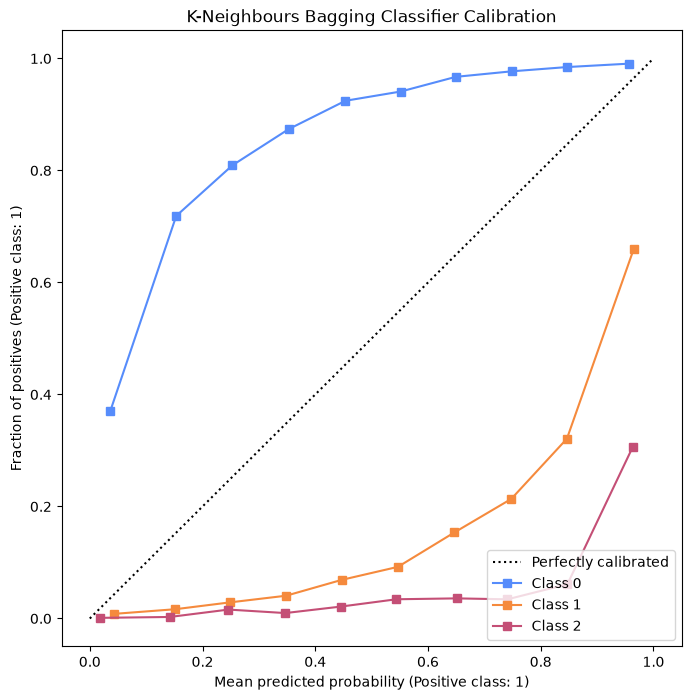

0 [0.9  0.99 0.42 ... 0.64 0.83 0.49]
1 [0.09 0.   0.58 ... 0.36 0.17 0.47]
2 [0.   0.01 0.   ... 0.   0.   0.04]


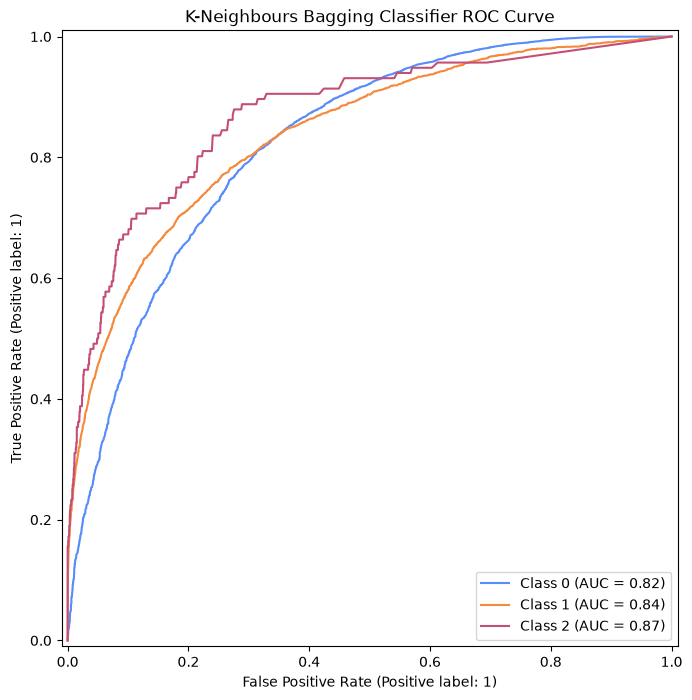

0 [0.9  0.99 0.42 ... 0.64 0.83 0.49]
1 [0.09 0.   0.58 ... 0.36 0.17 0.47]
2 [0.   0.01 0.   ... 0.   0.   0.04]


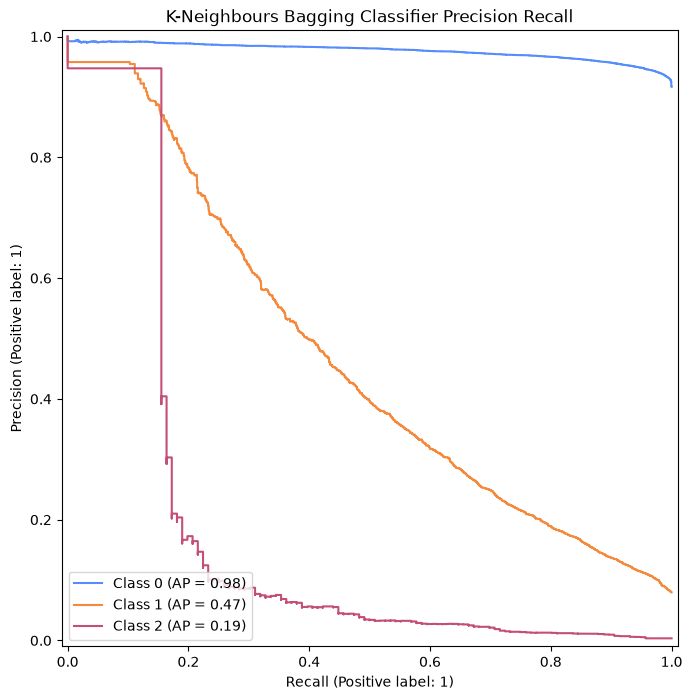

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [14]:
gc.collect()
torch.cuda.empty_cache()

primary_kneighbours_bagging_classifier_pipeline = _get_primary_build_model_pipeline()
primary_pipeline = run_kneighbours_bagging_classifier_pipeline(primary_kneighbours_bagging_classifier_pipeline,
                                                               primary_x_train,
                                                               primary_y_train,
                                                               primary_x_test,
                                                               primary_y_test)

primary_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12318.60it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

Random Forest Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                                  slice(None, None, None))],
                                  

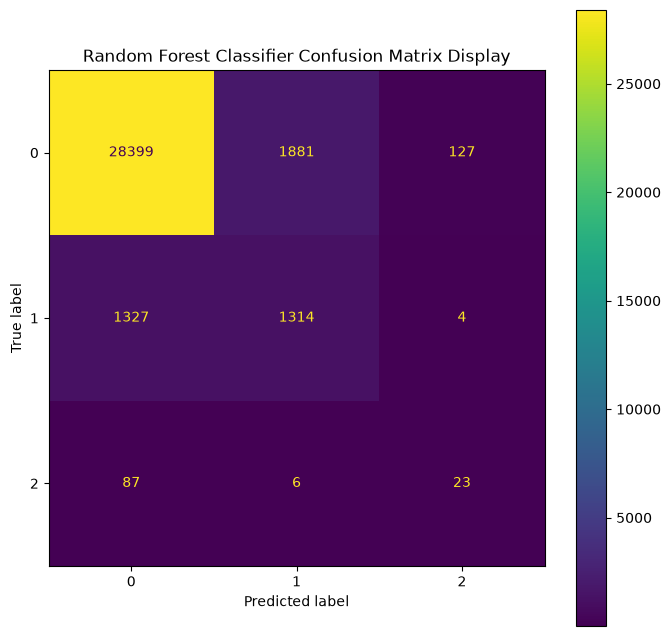

0 [0.94 0.95 0.61 ... 0.8  0.79 0.63]
1 [0.06 0.04 0.38 ... 0.2  0.21 0.36]
2 [0.   0.02 0.   ... 0.   0.   0.01]


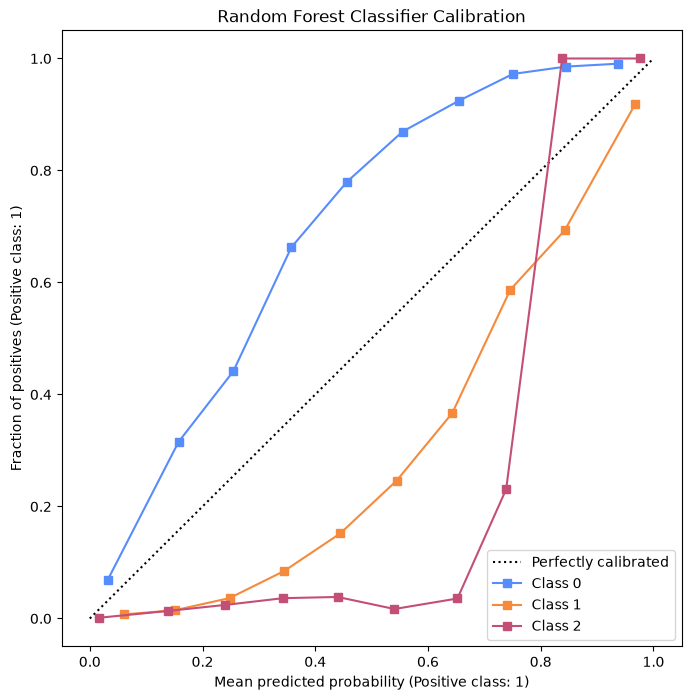

0 [0.94 0.95 0.61 ... 0.8  0.79 0.63]
1 [0.06 0.04 0.38 ... 0.2  0.21 0.36]
2 [0.   0.02 0.   ... 0.   0.   0.01]


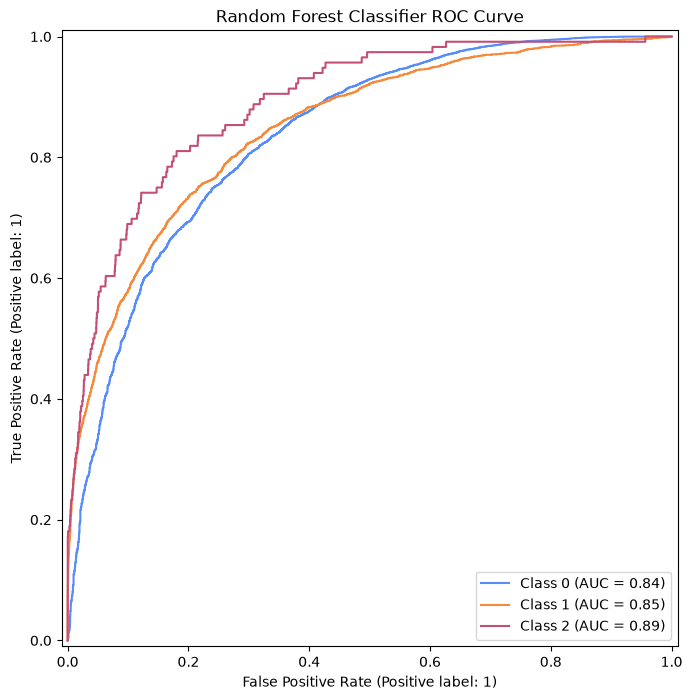

0 [0.94 0.95 0.61 ... 0.8  0.79 0.63]
1 [0.06 0.04 0.38 ... 0.2  0.21 0.36]
2 [0.   0.02 0.   ... 0.   0.   0.01]


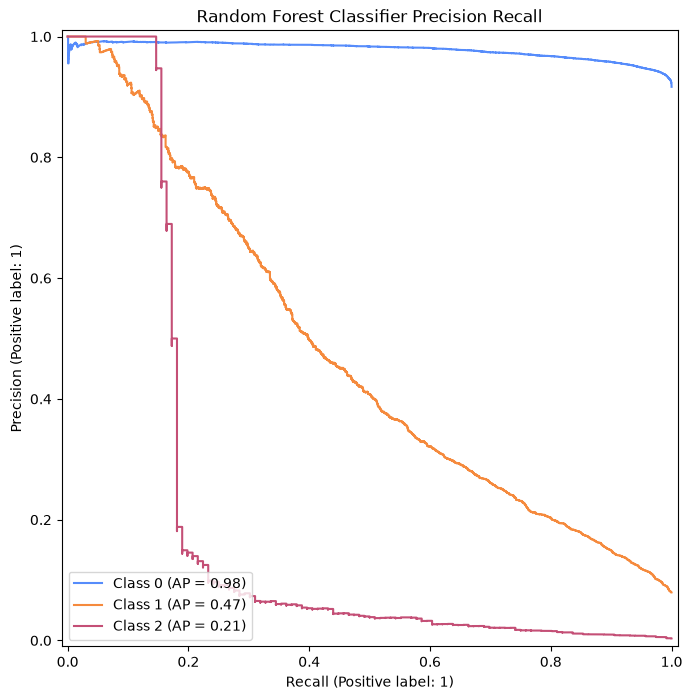

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [15]:
gc.collect()
torch.cuda.empty_cache()

primary_random_forest_classifier_pipeline = _get_primary_build_model_pipeline()
primary_pipeline = run_random_forest_pipeline(primary_random_forest_classifier_pipeline, primary_x_train,
                                              primary_y_train,
                                              primary_x_test,
                                              primary_y_test)

primary_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 23021.07it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

ADA Boost Decision Tree Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                                                                                    m

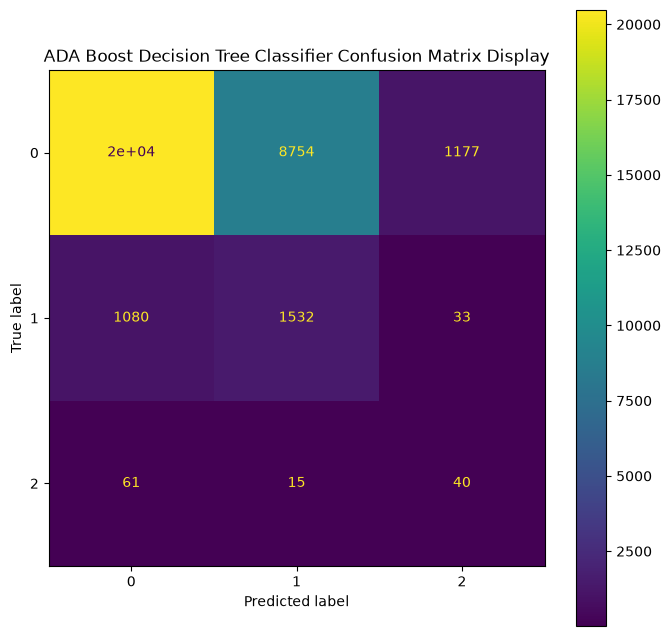

0 [0.36 0.35 0.36 ... 0.35 0.37 0.36]
1 [0.36 0.32 0.35 ... 0.37 0.37 0.35]
2 [0.28 0.32 0.29 ... 0.29 0.26 0.29]


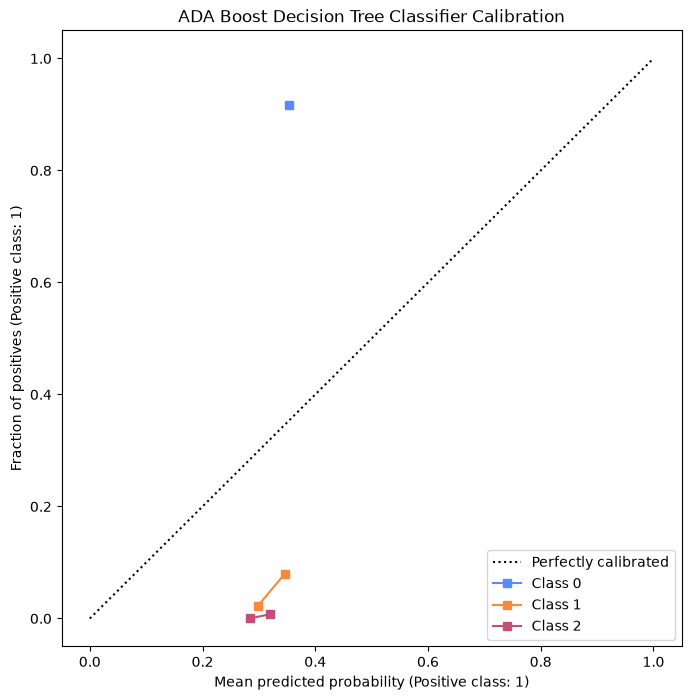

0 [0.36 0.35 0.36 ... 0.35 0.37 0.36]
1 [0.36 0.32 0.35 ... 0.37 0.37 0.35]
2 [0.28 0.32 0.29 ... 0.29 0.26 0.29]


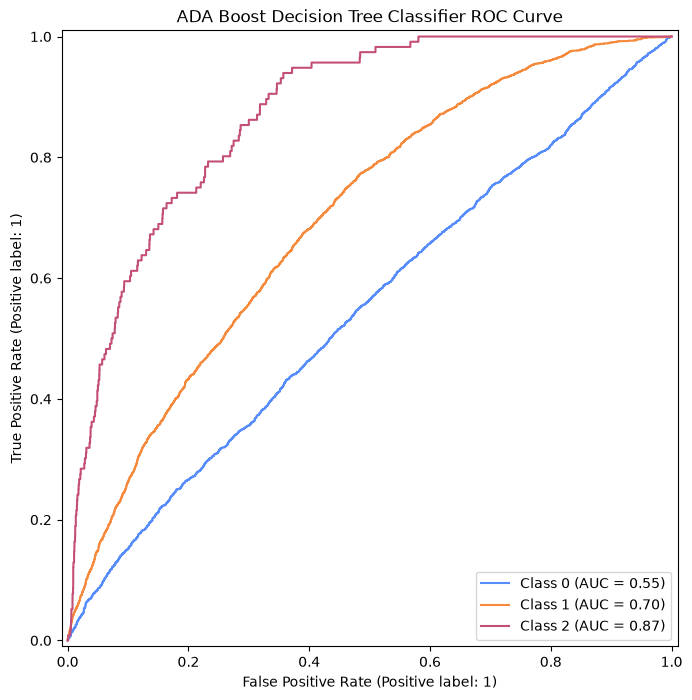

0 [0.36 0.35 0.36 ... 0.35 0.37 0.36]
1 [0.36 0.32 0.35 ... 0.37 0.37 0.35]
2 [0.28 0.32 0.29 ... 0.29 0.26 0.29]


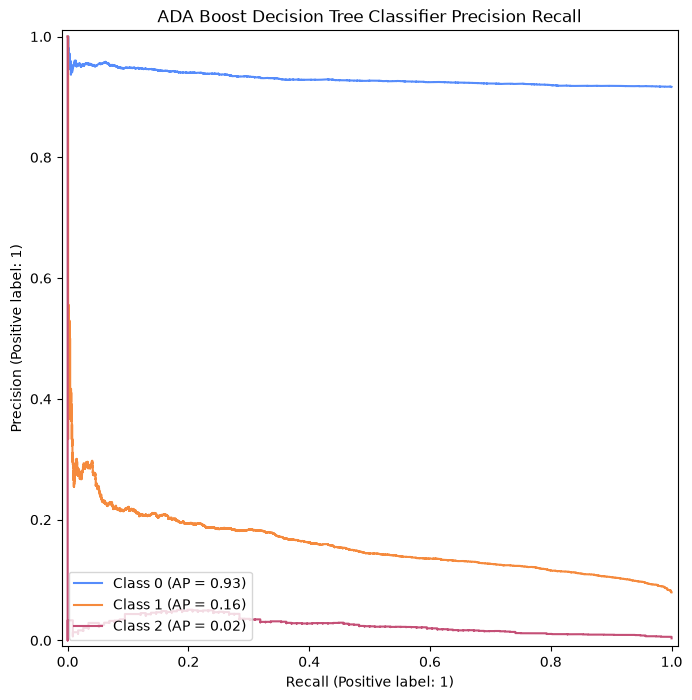

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [16]:
gc.collect()
torch.cuda.empty_cache()

primary_adaboost_decision_tree_pipeline = _get_primary_build_model_pipeline()
physical_pipeline = run_adaboost_decision_tree_pipeline(primary_adaboost_decision_tree_pipeline,
                                                        primary_x_train,
                                                        primary_y_train,
                                                        primary_x_test,
                                                        primary_y_test)

physical_pipeline

In [3]:
k_neighbours_estimator: RandomizedSearchCV = joblib.load(BAGGING_CLASSIFIER_KNEIGHBOURS_DUMP)

PermutationExplainer explainer: 51it [13:19:18, 959.18s/it]                           

SHAP explanation for class: Approve


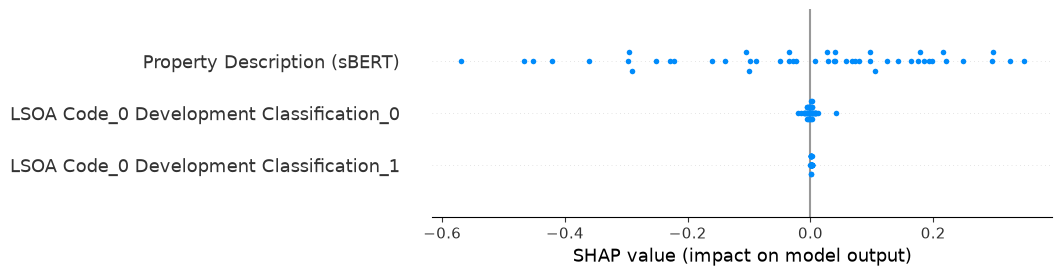

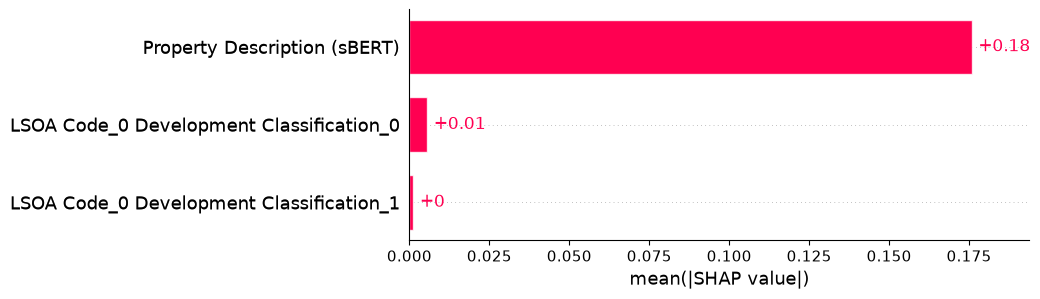

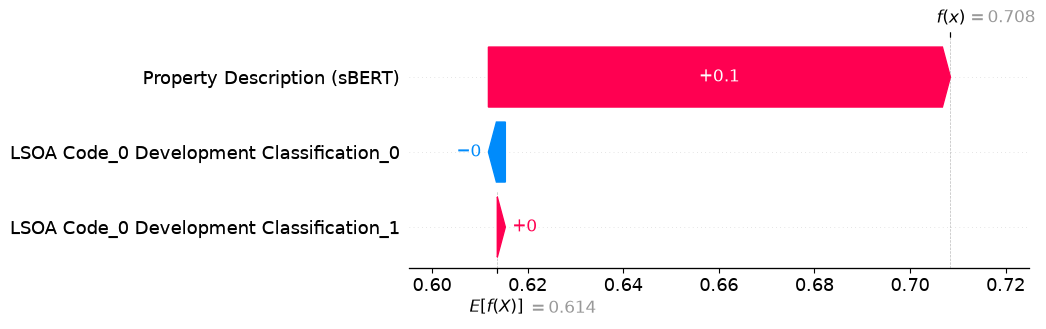

SHAP explanation for class: Refuse


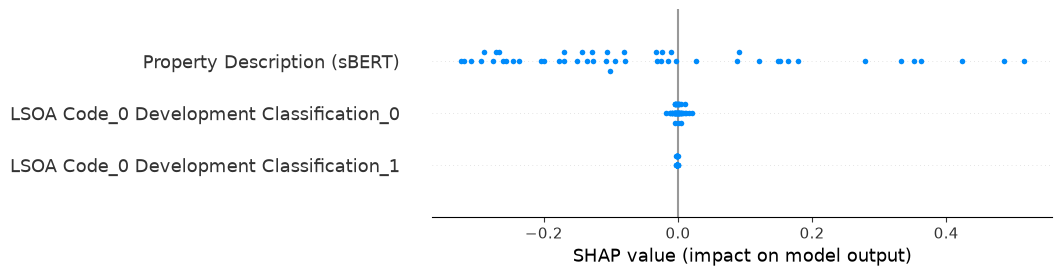

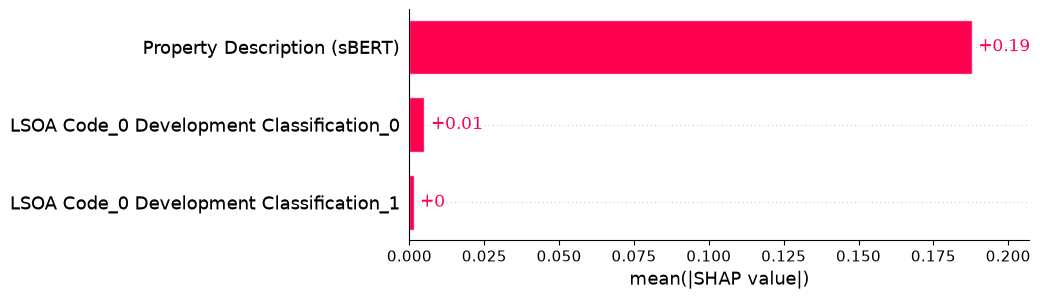

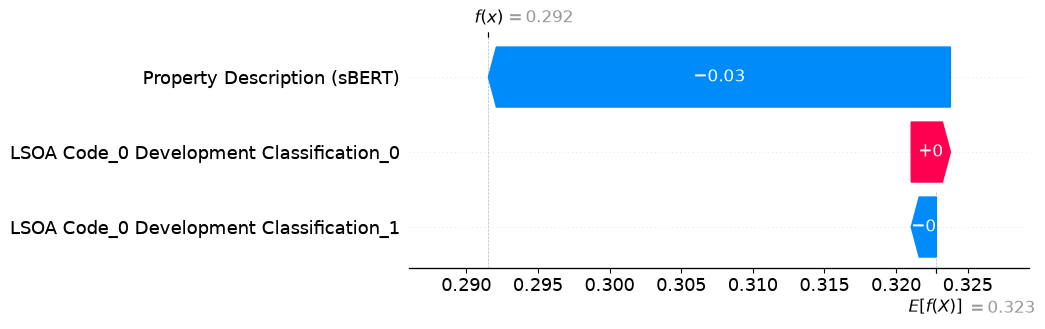

SHAP explanation for class: Split


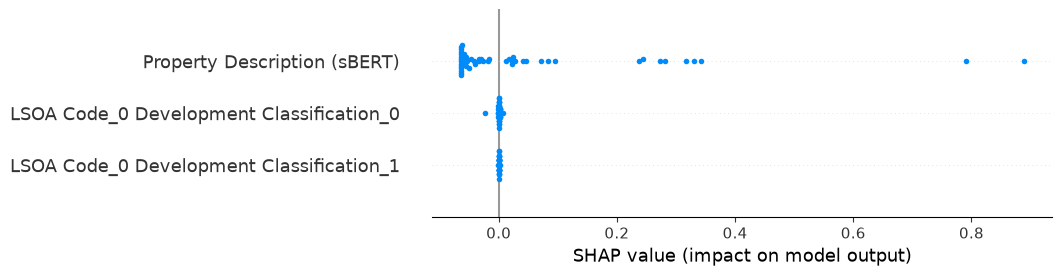

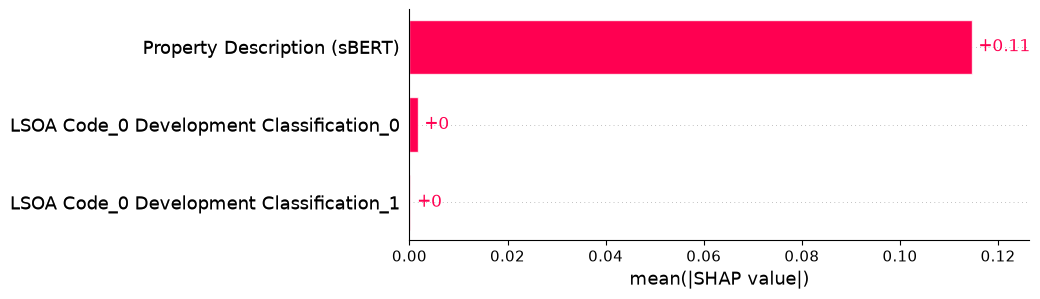

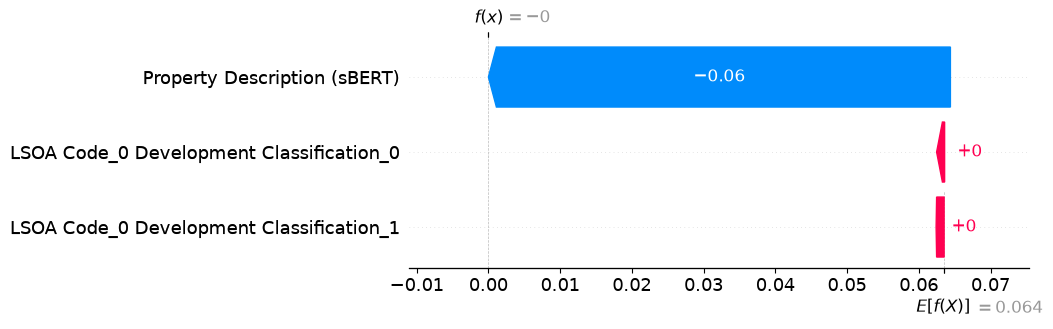

In [4]:
run_shap_analysis(k_neighbours_estimator.best_estimator_, primary_x_train, primary_x_test)

                 total  errors  error_rate  error_rate_pct
confidence_band                                           
(0.499, 0.6]      7845    2902    0.369917       36.991714
(0.6, 0.7]        7911    1944    0.245734       24.573379
(0.7, 0.8]        6721    1407    0.209344       20.934385
(0.8, 0.9]        4744     814    0.171585       17.158516
(0.9, 1.0]        4339     451    0.103941       10.394100


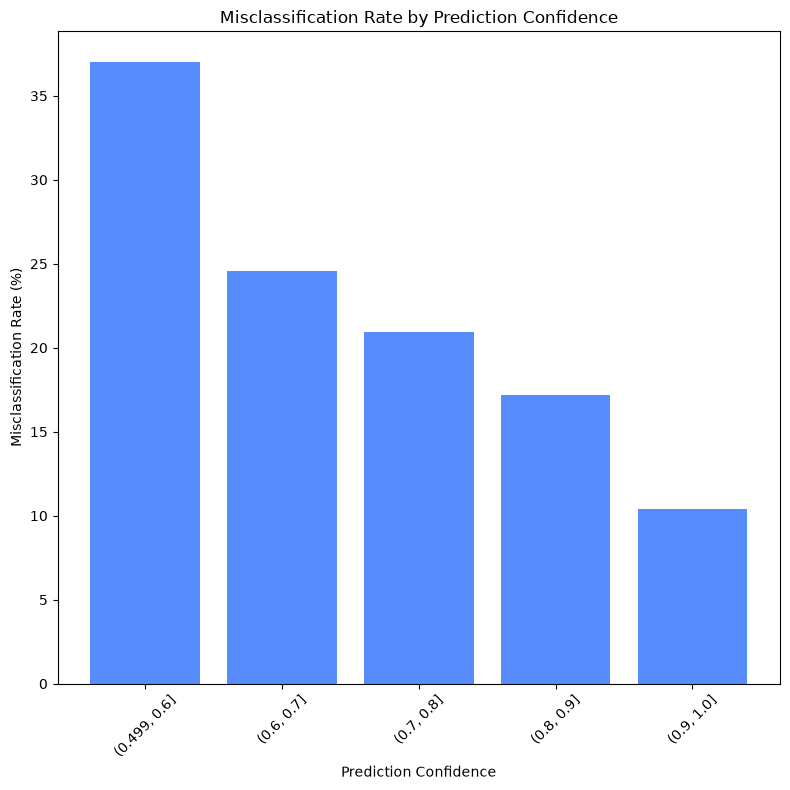

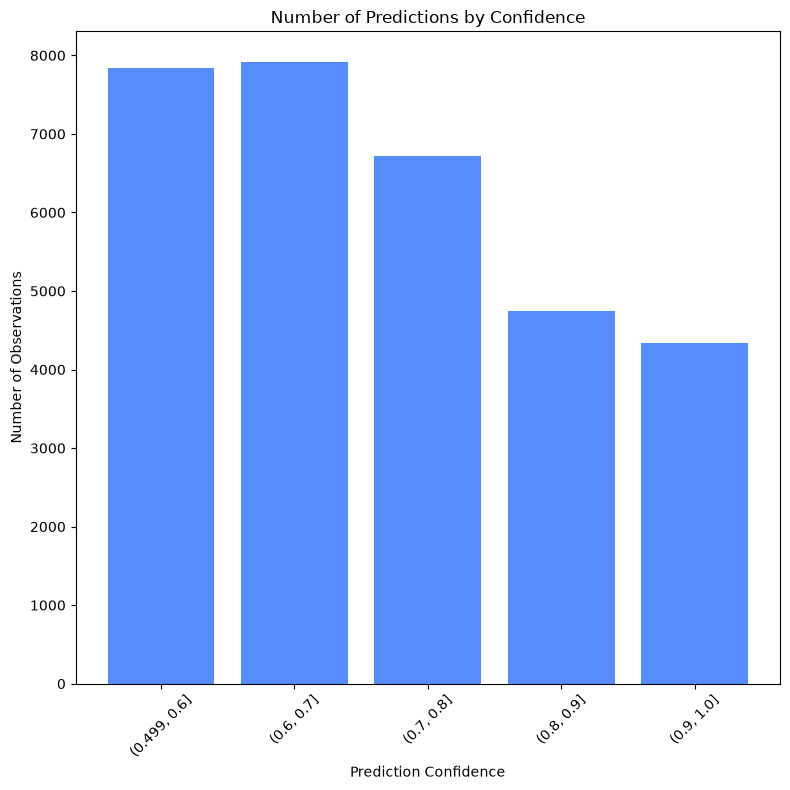

In [5]:
run_shap_inconsistency_analysis(k_neighbours_estimator.best_estimator_, primary_x_test, primary_y_test)